# Examen parcial: Generalización de políticas de RL ante diferentes niveles de fidelidad de simulación para trayectoria de nanoparticulas en arteria 

Alumno: Brayan Bruce Pérez Escobar

Curso: Proyecto de Investigación 2 (prof. Glen Rodríguez)


## 0. Preparación

In [1]:
import dataclasses
import json
import platform
import subprocess
import time
from datetime import datetime
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().parent              # el notebook está en notebooks/
TABLAS = ROOT / "results" / "tables"
FIGURAS = ROOT / "results" / "figures"
LOGS = ROOT / "logs"

pd.set_option("display.precision", 3)
plt.rcParams.update({"font.size": 10, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e4e3df", "figure.dpi": 110})
NIVEL_COLOR = {"R1": "#2a78d6", "R2": "#eb6834", "R3": "#1baf7a", "R4": "#eda100"}
T_INICIO = time.time()


def run_metadata():
    commit = subprocess.run(["git", "rev-parse", "--short", "HEAD"], cwd=ROOT,
                            capture_output=True, text=True).stdout.strip()
    cambios = subprocess.run(["git", "status", "--porcelain"], cwd=ROOT,
                             capture_output=True, text=True).stdout.strip()
    return {"fecha": datetime.now().isoformat(timespec="seconds"),
            "git_commit": commit + (" (con cambios sin commit)" if cambios else ""),
            "python": platform.python_version(),
            "plataforma": platform.platform(),
            "numpy": np.__version__,
            "pandas": pd.__version__}


print(json.dumps(run_metadata(), indent=2, ensure_ascii=False))

{
  "fecha": "2026-11-12T22:26:03",
  "git_commit": "99a45e1 (con cambios sin commit)",
  "python": "3.12.7",
  "plataforma": "Windows-11-10.0.26300-SP0",
  "numpy": "2.5.3",
  "pandas": "3.0.6"
}


## 1. Introducción

### 1.1 Problema

Un enjambre de nanopartículas magnéticas se libera en un vaso sanguíneo que se bifurca en Y y debe llegar a la rama objetivo. Una fuerza externa de control, común a todas las partículas, lo dirige; el agente de RL (PPO) decide esa fuerza en cada paso.

Se definen cuatro niveles de fidelidad:

| Nivel | Física |
|---|---|
| R1 | Sin flujo |
| R2 | Flujo estacionario (Poiseuille) |
| R3 | Flujo pulsátil |
| R4 | Flujo pulsátil + movimiento browniano |

**Pregunta:** ¿puede un currículo progresivo de fidelidad (R1→R4) mejorar la generalización de la política frente a entrenar en un único nivel?

### 1.2 Objetivos

**General:** determinar si una política PPO entrenada con currículo R1→R4 reduce la brecha de fidelidad media frente a las políticas entrenadas en un único nivel, con el mismo presupuesto de interacciones.

| | Objetivo específico | Estado |
|---|---|---|
| OE1 | Fijar los cuatro niveles de modo que sean distinguibles para el control y que la recompensa esté alineada con η | Sprints 1–2; R2 y R3 aún no se distinguen en η |
| OE2 | Construir la matriz de evaluación cruzada 4×4 (entrenar en Ri, evaluar en Rj) | Pendiente |
| OE3 | Entrenar PPO con currículo R1→R4 y compararlo con las políticas de un solo nivel | Pendiente |
| OE4 | Medir la importancia por permutación de cada variable de la observación dentro y fuera del nivel de entrenamiento | Sprints 3–4 |
| OE5 (extensión) | Repetir la matriz 4×4 con DreamerV3 | Pendiente |

### 1.3 Hipótesis

| | Hipótesis | Se refuta si |
|---|---|---|
| General | El currículo tiene un FidelityGap medio al menos 0.05 menor que la mejor política de un solo nivel (IC 95 % sin el 0) | La diferencia es menor a 0.05 o su IC incluye el 0 |
| H1 | Cada par de niveles consecutivos produce un η distinto en al menos una política de referencia (IC 95 % sin solaparse), y Spearman retorno–η ≥ 0.9 en cada nivel | Algún par consecutivo no se distingue |
| H2 | La brecha es asimétrica: en al menos un par, el FidelityGap Ri→Rj difiere en ≥ 0.05 del de Rj→Ri | Ningún par cumple esa diferencia |
| H3 | El currículo reduce el FidelityGap medio en ≥ 0.05 sin perder más de 0.05 de η en R4 | No reduce la brecha o pierde η en R4 |
| H4 | Las variables que dependen del nivel (fase del pulso, margen de control) tienen importancia ≤ −0.05 fuera del nivel de entrenamiento, y quitarlas baja el FidelityGap en ≥ 0.05 | Al quitarlas la brecha no baja |

### 1.4 Variables

| Tipo | Variable |
|---|---|
| Independientes | Régimen de entrenamiento (un nivel Ri o currículo); nivel de evaluación Rj; conjunto de variables de la observación |
| Dependiente | Generalización de la política |
| Métrica principal | η = N_objetivo / N, fracción del enjambre que llega a la rama objetivo |
| Métricas secundarias | Fracción perdida en la otra rama, tiempo de tránsito, esfuerzo de control, eficiencia muestral, estabilidad entre semillas |
| Brecha | FidelityGap(Ri→Rj) = η(Ri, Ri) − η(Ri, Rj) |


### 2. Asignacion de valores

In [2]:
# Niveles de fidelidad: tipo de flujo y si hay movimiento browniano
NIVELES = {
    "R1": {"flujo": "ninguno",     "browniano": False},
    "R2": {"flujo": "estacionario", "browniano": False},
    "R3": {"flujo": "pulsatil",    "browniano": False},
    "R4": {"flujo": "pulsatil",    "browniano": True},
}

# Física del entorno v0.2 (Var3), en unidades adimensionales (ancho del vaso W = 1, U_max = 1)
FISICA = {
    "u_max": 1.0,             # velocidad del flujo en el centro del canal
    "pulse_amplitude": 0.9,   # A en U(t) = U_max (1 + A sin(2πt/T)), solo R3 y R4
    "pulse_period": 20.0,     # T
    "v_mag": 0.3,             # F_max: velocidad máxima que imprime la fuerza de control
    "diffusion": 0.01,        # D del browniano, solo R4
    "dt": 0.05,               # paso de integración
    "particle_radius": 0.05,  # a: radio de la partícula
}

# Geometría: canal madre que se divide en dos ramas a ±30°; la de arriba es la objetivo
GEOMETRIA = {"width": 1.0, "parent_length": 5.0, "branch_length": 4.0, "theta_deg": 30.0}

# Pesos de la recompensa (Var1 del Sprint 2)
RECOMPENSA = {"progress": 0.1, "target": 1.0, "other": 0.5, "effort": 0.0001}

# Episodio
N_PARTICULAS = 200
HORIZONTE = 800        # pasos máximos
FIN_FRACCION = 0.95    # el episodio termina cuando el 95 % del enjambre salió por alguna rama

# Semillas: se escriben tal cual se usan, sin sumarles nada
SEMILLAS = {
    # Episodios para decidir (pesos de la recompensa, hiperparámetros, features): validación
    "ajuste":  list(range(5_000, 5_020)),
    # Episodios solo para los resultados finales; nunca se usan para decidir: prueba
    "reporte": list(range(9_000, 9_030)),
}
# Semilla de PPO de cada corrida (Sprints 3–4): fija la inicialización de la red y la exploración.
# Cada una es una corrida independiente, el equivalente a un fold. Los 4 entornos de entrenamiento
# de una corrida empiezan con semilla_ppo + 0, 1, 2, 3 (lo asigna Stable-Baselines3).
SEMILLAS_PPO = [1000, 1001, 1002]

pd.DataFrame({"flujo": {r: v["flujo"] for r, v in NIVELES.items()},
              "browniano": {r: v["browniano"] for r, v in NIVELES.items()}})

,flujo,browniano
R1,ninguno,False
R2,estacionario,False
R3,pulsatil,False
R4,pulsatil,True


In [77]:
# Comprobación: los valores de arriba son los mismos que usa el código del proyecto
from nanoswarm.envs.dynamics import CONDITIONS, YBifurcation
from nanoswarm.envs.vascular_env import VascularEnv
from nanoswarm.evaluation import episode_seeds
from nanoswarm.variants import VARIANTS

var3 = VARIANTS["var3"]
geom = YBifurcation()
env = VascularEnv()
assert dataclasses.asdict(var3.physics) == FISICA
assert dataclasses.asdict(var3.reward) == RECOMPENSA
assert var3.horizon == HORIZONTE and env.n_particles == N_PARTICULAS and env.done_fraction == FIN_FRACCION
assert (geom.width, geom.parent_length, geom.branch_length) == tuple(list(GEOMETRIA.values())[:3])
assert all(CONDITIONS[r].brownian == v["browniano"] for r, v in NIVELES.items())
assert SEMILLAS["ajuste"] == episode_seeds("ajuste") and SEMILLAS["reporte"] == episode_seeds("reporte")
assert not set(SEMILLAS["ajuste"]) & set(SEMILLAS["reporte"])
entornos_entrenamiento = {s + i for s in SEMILLAS_PPO for i in range(4)}
assert not entornos_entrenamiento & (set(SEMILLAS["ajuste"]) | set(SEMILLAS["reporte"]))
print("Valores asignados")

Valores asignados


## 3. Datos


Para la Geometría, cada tramo (madre, rama objetivo, otra rama) se describe por su línea central. `proyectar` asigna cada partícula al tramo más cercano y devuelve su posición a lo largo del tramo (t) y su distancia lateral a la línea central (s).

In [78]:
MADRE, OBJETIVO, OTRA = 0, 1, 2           # índices de tramo
ACTIVA, EN_OBJETIVO, EN_OTRA = 0, 1, 2    # estado de cada partícula

MEDIO_ANCHO = GEOMETRIA["width"] / 2
L_MADRE, L_RAMA = GEOMETRIA["parent_length"], GEOMETRIA["branch_length"]
THETA = np.deg2rad(GEOMETRIA["theta_deg"])

UNION = np.array([L_MADRE, 0.0])          # punto de la bifurcación
ORIGENES = np.array([[0.0, 0.0], UNION, UNION])
TANGENTES = np.array([[1.0, 0.0], [np.cos(THETA), np.sin(THETA)], [np.cos(THETA), -np.sin(THETA)]])
NORMALES = np.stack([-TANGENTES[:, 1], TANGENTES[:, 0]], axis=1)   # tangente girada +90°
LARGOS = np.array([L_MADRE, L_RAMA, L_RAMA])


def proyectar(pos):
    # Tramo más cercano a cada punto, coordenada t a lo largo de él y distancia lateral s
    rel = pos[:, None, :] - ORIGENES[None, :, :]
    t = np.einsum("nkd,kd->nk", rel, TANGENTES)
    s = np.einsum("nkd,kd->nk", rel, NORMALES)
    t_recortado = np.clip(t, 0.0, LARGOS)
    distancia = np.hypot(t - t_recortado, s)
    tramo = np.argmin(distancia, axis=1)
    i = np.arange(len(pos))
    return tramo, t[i, tramo], s[i, tramo]


def a_xy(tramo, t, s):
    return ORIGENES[tramo] + t[:, None] * TANGENTES[tramo] + s[:, None] * NORMALES[tramo]


def dentro(tramo, t, s, medio_ancho):
    return (np.abs(s) <= medio_ancho) & ~((tramo == MADRE) & (t < 0))


def distancia_al_objetivo(tramo, t):
    # Distancia sobre la línea central hasta la salida de la rama objetivo
    d_madre = (L_MADRE - np.clip(t, 0, L_MADRE)) + L_RAMA
    d_objetivo = L_RAMA - np.clip(t, 0, L_RAMA)
    d_otra = np.clip(t, 0, L_RAMA) + L_RAMA     # volver a la bifurcación y subir
    return np.select([tramo == MADRE, tramo == OBJETIVO], [d_madre, d_objetivo], d_otra)


def posiciones_iniciales(n, rng):
    # Enjambre liberado en la entrada, repartido a lo ancho del canal
    t = rng.uniform(0.0, 0.2 * GEOMETRIA["width"], n)
    s = rng.uniform(-0.45 * GEOMETRIA["width"], 0.45 * GEOMETRIA["width"], n)
    return a_xy(np.zeros(n, dtype=int), t, s)

Para la física, en cada paso Δt, cada partícula activa se mueve con el flujo más la fuerza de control (y el browniano en R4); las paredes la reflejan. Una partícula se entrega cuando cruza el extremo de una rama. Aquí es donde se diferencian los niveles: 
- velocidad_centro (flujo)
- el término browniano.

In [5]:
def velocidad_centro(nivel, tiempo):
    # U(t): 0 en R1, U_max en R2, U_max (1 + A sin(2πt/T)) en R3 y R4
    flujo = NIVELES[nivel]["flujo"]
    if flujo == "ninguno":
        return 0.0
    if flujo == "estacionario":
        return FISICA["u_max"]
    fase = 2 * np.pi * tiempo / FISICA["pulse_period"]
    return FISICA["u_max"] * (1 + FISICA["pulse_amplitude"] * np.sin(fase))


def velocidad_flujo(tramo, s, u_centro):
    # Perfil de Poiseuille u(s) = U (1 - (2s/W)²), en la dirección del tramo
    perfil = np.clip(1 - (s / MEDIO_ANCHO) ** 2, 0.0, None)
    return (u_centro * perfil)[:, None] * TANGENTES[tramo]


def paso_fisico(nivel, pos, estado, fuerza, tiempo, rng):
    activas = estado == ACTIVA
    if not activas.any():
        return pos, estado

    p = pos[activas]
    tramo, _, s = proyectar(p)
    velocidad = velocidad_flujo(tramo, s, velocidad_centro(nivel, tiempo)) + FISICA["v_mag"] * fuerza
    nueva = p + velocidad * FISICA["dt"]
    if NIVELES[nivel]["browniano"]:
        nueva = nueva + np.sqrt(2 * FISICA["diffusion"] * FISICA["dt"]) * rng.standard_normal(nueva.shape)

    # Paredes reflectantes a distancia a (radio de la partícula); si aun así queda fuera, no se mueve
    pared = MEDIO_ANCHO - FISICA["particle_radius"]
    tramo, t, s = proyectar(nueva)
    fuera = np.abs(s) > pared
    s = np.where(fuera, np.sign(s) * (2 * pared - np.abs(s)), s)
    t = np.where((tramo == MADRE) & (t < 0), -t, t)
    nueva = a_xy(tramo, t, s)
    tramo, t, s = proyectar(nueva)
    mal = ~dentro(tramo, t, s, pared)
    nueva[mal] = p[mal]
    tramo, t, s = proyectar(nueva)

    # Entrega: cruza el extremo de una rama
    nuevo_estado = np.full(len(p), ACTIVA)
    salio = (tramo != MADRE) & (t >= L_RAMA)
    nuevo_estado[salio & (tramo == OBJETIVO)] = EN_OBJETIVO
    nuevo_estado[salio & (tramo == OTRA)] = EN_OTRA

    pos, estado = pos.copy(), estado.copy()
    pos[activas] = nueva
    estado[activas] = nuevo_estado
    return pos, estado

### Observación, recompensa y episodio

El agente no ve las 200 partículas, sino 11 estadísticas del enjambre (diccionario en 3.6). La recompensa es

$$r_t = w_p\,\Delta d + w_e\,\Delta\eta_{obj} - w_m\,\Delta\eta_{otra} - w_u\,\lVert a_t\rVert^2$$

donde Δd es cuánto se acercó el enjambre a la salida objetivo (distancia sobre la línea central, normalizada). El episodio termina cuando sale el 95 % del enjambre o a los 800 pasos.

In [79]:
NOMBRES_OBS = ["centroid_x", "centroid_y", "spread_x", "spread_y",
               "frac_target", "frac_other", "frac_active",
               "phase_sin", "phase_cos", "prev_action_x", "prev_action_y"]


def observacion(pos, estado, tiempo, accion_previa):
    activas = estado == ACTIVA
    if activas.any():
        centroide = pos[activas].mean(axis=0) - UNION    # relativo a la bifurcación
        dispersion = pos[activas].std(axis=0)
    else:
        centroide, dispersion = np.zeros(2), np.zeros(2)
    fase = 2 * np.pi * tiempo / FISICA["pulse_period"]
    return np.concatenate([centroide, dispersion,
                           [(estado == EN_OBJETIVO).mean(), (estado == EN_OTRA).mean(), activas.mean()],
                           [np.sin(fase), np.cos(fase)], accion_previa]).astype(np.float32)


def distancia_media(pos):
    tramo, t, _ = proyectar(pos)
    return distancia_al_objetivo(tramo, t).mean() / (L_MADRE + L_RAMA)


class EntornoEnjambre:
    # Mismo funcionamiento que el entorno Gymnasium del proyecto: reset(semilla) y step(acción)

    def __init__(self, nivel):
        self.nivel = nivel

    def reset(self, semilla=None, rng=None):
        # rng: generador ya creado (lo usa el envoltorio de Gymnasium de la sección 4)
        self.rng = rng if rng is not None else np.random.default_rng(semilla)
        self.pos = posiciones_iniciales(N_PARTICULAS, self.rng)
        self.estado = np.full(N_PARTICULAS, ACTIVA)
        self.tiempo, self.pasos = 0.0, 0
        self.accion_previa = np.zeros(2)
        self.tiempo_salida = np.full(N_PARTICULAS, np.nan)
        self.suma_esfuerzo = 0.0
        self.dist = distancia_media(self.pos)
        return observacion(self.pos, self.estado, self.tiempo, self.accion_previa)

    def step(self, accion):
        accion = np.clip(np.asarray(accion, dtype=float), -1.0, 1.0)
        fuerza = accion / max(1.0, np.linalg.norm(accion))        # norma ≤ 1

        estado_previo, dist_previa = self.estado, self.dist
        self.pos, self.estado = paso_fisico(self.nivel, self.pos, self.estado, fuerza, self.tiempo, self.rng)
        self.tiempo += FISICA["dt"]
        self.pasos += 1
        self.tiempo_salida[(estado_previo == ACTIVA) & (self.estado != ACTIVA)] = self.tiempo
        self.suma_esfuerzo += float(fuerza @ fuerza)
        self.dist = distancia_media(self.pos)

        terminos = {
            "progress": RECOMPENSA["progress"] * (dist_previa - self.dist),
            "target": RECOMPENSA["target"] * ((self.estado == EN_OBJETIVO).mean() - (estado_previo == EN_OBJETIVO).mean()),
            "other": -RECOMPENSA["other"] * ((self.estado == EN_OTRA).mean() - (estado_previo == EN_OTRA).mean()),
            "effort": -RECOMPENSA["effort"] * float(np.dot(fuerza, fuerza)),
        }
        self.accion_previa = fuerza

        terminado = bool((self.estado != ACTIVA).mean() >= FIN_FRACCION)
        truncado = self.pasos >= HORIZONTE and not terminado
        info = {"eta": float((self.estado == EN_OBJETIVO).mean()),
                "eta_other": float((self.estado == EN_OTRA).mean()),
                "frac_active": float((self.estado == ACTIVA).mean()),
                "steps": self.pasos,
                "transit": float(np.nanmean(self.tiempo_salida)) if np.isfinite(self.tiempo_salida).any() else np.nan,
                "effort": self.suma_esfuerzo / max(self.pasos, 1)}
        obs = observacion(self.pos, self.estado, self.tiempo, self.accion_previa)
        return obs, float(sum(terminos.values())), terminado, truncado, info

### Políticas que generan las trayectorias

Para generar datos hace falta una política. Antes de PPO se usan cuatro políticas fijas, que no aprenden y por eso se comportan igual en todos los niveles (son el baseline de la sección 4):

| Política | Qué hace |
|---|---|
| `zero` | No aplica fuerza: el enjambre se reparte solo con el flujo |
| `random` | Fuerza al azar en cada paso |
| `heur_perp` | Cerca de la bifurcación, empuja de lado hacia la rama objetivo |
| `heur_branch` | Empuja siempre en la dirección de la rama objetivo |

In [85]:
LADO = NORMALES[MADRE] * np.sign(TANGENTES[OBJETIVO] @ NORMALES[MADRE])   # hacia el lado de la rama objetivo
ANTICIPACION = 2.0   # heur_perp actúa cuando el centroide está a menos de 2 W antes de la bifurcación


def crear_politica(nombre, semilla):
    if nombre == "zero":
        return lambda obs: np.zeros(2)
    if nombre == "random":
        rng = np.random.default_rng(semilla + 10_000)   # generador propio, distinto al del entorno
        return lambda obs: rng.uniform(-1.0, 1.0, size=2)
    if nombre == "heur_perp":
        return lambda obs: LADO.copy() if -ANTICIPACION <= obs[0] <= 0.0 else np.zeros(2)
    if nombre == "heur_branch":
        return lambda obs: TANGENTES[OBJETIVO].copy()
    raise ValueError(nombre)


POLITICAS = ["zero", "random", "heur_perp", "heur_branch"]


def correr_episodio(nivel, politica, semilla, registrar=False):
    # Corre un episodio; con registrar=True devuelve también la trayectoria paso a paso
    entorno = EntornoEnjambre(nivel)
    pi = crear_politica(politica, semilla)
    obs = entorno.reset(semilla)
    retorno, filas, terminado, truncado = 0.0, [], False, False
    while not (terminado or truncado):
        accion = pi(obs)
        obs_siguiente, r, terminado, truncado, info = entorno.step(accion)
        retorno += r
        if registrar:
            filas.append({"paso": info["steps"], **dict(zip(NOMBRES_OBS, obs)),
                          "accion_x": accion[0], "accion_y": accion[1], "recompensa": r,
                          "eta": info["eta"], "eta_otra": info["eta_other"], "activas": info["frac_active"]})
        obs = obs_siguiente
    resumen = {"nivel": nivel, "politica": politica, "semilla": semilla, "eta": info["eta"],
               "perdida": info["eta_other"], "atascada": info["frac_active"], "pasos": info["steps"],
               "transito": info["transit"], "esfuerzo": info["effort"], "retorno": retorno}
    return (resumen, pd.DataFrame(filas)) if registrar else resumen

### Verificacion de codigo, reproducibiidad

Se corren las 4 políticas en los 4 niveles con 3 semillas de ajuste, con el simulador de este notebook y con el del proyecto (`nanoswarm`). Con esto revisamos que el simulador es el mismo que el usado en las anteriores semanas y que queda demostrado que todo lo que se mide en las secciones 5 a 7 está en el mismo entorno donde se entrenaron.

In [8]:
from nanoswarm.baselines import make_policy
from nanoswarm.evaluation import make_env
from nanoswarm.utils.rollout import run_episode

SEMILLAS_PRUEBA = SEMILLAS["ajuste"][:3]
t0 = time.time()
filas = []
for nivel in NIVELES:
    entorno_proyecto = make_env(var3, nivel)
    for politica in POLITICAS:
        for semilla in SEMILLAS_PRUEBA:
            nb_ = correr_episodio(nivel, politica, semilla)
            pr = run_episode(entorno_proyecto, make_policy(politica, entorno_proyecto, seed=semilla + 10_000), semilla)
            filas.append({**nb_, "eta_proyecto": pr["eta"], "pasos_proyecto": pr["steps"],
                          "retorno_proyecto": pr["return"]})
comprobacion = pd.DataFrame(filas)

dif = {"eta": (comprobacion["eta"] - comprobacion["eta_proyecto"]).abs().max(),
       "pasos": (comprobacion["pasos"] - comprobacion["pasos_proyecto"]).abs().max(),
       "retorno": (comprobacion["retorno"] - comprobacion["retorno_proyecto"]).abs().max()}
print(f"{len(comprobacion)} episodios en {time.time() - t0:.0f} s. Diferencia máxima: {dif}")
assert dif["eta"] == 0 and dif["pasos"] == 0 and dif["retorno"] < 1e-9
print("El simulador del notebook da los mismos resultados que el del proyecto.")
comprobacion.groupby(["nivel", "politica"], sort=False)[["eta", "eta_proyecto", "pasos"]].mean().unstack("politica")

48 episodios en 51 s. Diferencia máxima: {'eta': np.float64(0.0), 'pasos': np.int64(0), 'retorno': np.float64(0.0)}
El simulador del notebook da los mismos resultados que el del proyecto.


eta                              eta_proyecto                   \
politica   zero random heur_perp heur_branch         zero random heur_perp   
nivel                                                                        
R1        0.000  0.000      0.00       0.983        0.000  0.000      0.00   
R2        0.473  0.487      0.95       0.955        0.473  0.487      0.95   
R3        0.473  0.523      0.95       0.950        0.473  0.523      0.95   
R4        0.508  0.520      0.85       0.865        0.508  0.520      0.85   

                        pasos                                 
politica heur_branch     zero   random heur_perp heur_branch  
nivel                                                         
R1             0.983  800.000  800.000   800.000     634.000  
R2             0.955  604.000  436.000   735.667     360.667  
R3             0.950  527.000  449.000   623.333     348.000  
R4             0.865  258.667  270.667   277.333     194.000

### 3.1 Tamaño y esquema

In [86]:
resumen_ejemplo, trayectoria = correr_episodio("R3", "heur_branch", SEMILLAS["ajuste"][0], registrar=True)
print(f"Filas (pasos): {len(trayectoria)}   Columnas: {trayectoria.shape[1]}   η final: {resumen_ejemplo['eta']:.3f}")
trayectoria.iloc[::50]

Filas (pasos): 347   Columnas: 18   η final: 0.950


,paso,centroid_x,centroid_y,spread_x,spread_y,frac_target,frac_other,frac_active,phase_sin,phase_cos,prev_action_x,prev_action_y,accion_x,accion_y,recompensa,eta,eta_otra,activas
0,1,-4.899,-0.002,0.055,0.266,0.000,0.0,1.000,0.000e+00,1.000e+00,0.000,0.0,0.866,0.5,4.421e-04,0.000,0.0,1.000
50,51,-2.108,0.290,0.897,0.177,0.000,0.0,1.000,7.071e-01,7.071e-01,0.866,0.5,0.866,0.5,5.325e-04,0.000,0.0,1.000
100,101,0.466,1.009,1.996,0.663,0.000,0.0,1.000,1.000e+00,3.170e-15,0.866,0.5,0.866,0.5,5.536e-03,0.005,0.0,0.995
150,151,0.656,0.926,0.953,0.512,0.355,0.0,0.645,7.071e-01,-7.071e-01,0.866,0.5,0.866,0.5,1.415e-04,0.355,0.0,0.645
200,201,1.635,1.457,0.699,0.403,0.450,0.0,0.550,-2.098e-15,-1.000e+00,0.866,0.5,0.866,0.5,5.056e-03,0.455,0.0,0.545
250,251,2.250,1.812,0.396,0.228,0.585,0.0,0.415,-7.071e-01,-7.071e-01,0.866,0.5,0.866,0.5,-1.320e-05,0.585,0.0,0.415
300,301,2.742,2.097,0.198,0.113,0.720,0.0,0.280,-1.000e+00,2.469e-14,0.866,0.5,0.866,0.5,-5.009e-05,0.720,0.0,0.280


El tamaño de los datos depende de cuántos episodios se corren. Con las políticas de referencia, la partición de ajuste son 320 episodios (20 semillas × 4 políticas × 4 niveles) y la de reporte 480 (30 × 4 × 4). Para pasarlo a pasos, que son las filas de los datos, se multiplica por la duración media de un episodio en cada nivel, estimada con los 48 episodios ya corridos en la comprobación 

In [87]:
pasos_por_nivel = comprobacion.groupby("nivel")["pasos"].mean()
tamano = pd.DataFrame([{"partición": nombre, "semillas": f"{s[0]}–{s[-1]}", "episodios por nivel y política": len(s),
                        "episodios": len(s) * len(NIVELES) * len(POLITICAS),
                        "pasos (aprox.)": round(len(s) * len(POLITICAS) * pasos_por_nivel.sum())}
                       for nombre, s in SEMILLAS.items()]).set_index("partición")
print("Pasos medios por episodio y nivel:", pasos_por_nivel.round(0).to_dict())
tamano

Pasos medios por episodio y nivel: {'R1': 758.0, 'R2': 534.0, 'R3': 487.0, 'R4': 250.0}


,semillas,episodios por nivel y política,episodios,pasos (aprox.)
partición,,,,
ajuste,5000–5019,20,320,162367
reporte,9000–9029,30,480,243550


### Diccionario

El rango observado sale de la trayectoria de ejemplo.
| Variable | Tipo | Descripción | Mín | Máx |
|---|---|---|---|---|
| `paso` | índice | Número de paso dentro del episodio | 1 | 347 |
| `centroid_x` | observación | Posición media de las partículas activas en x, relativa a la bifurcación (negativa antes de llegar) | −4.899 | 3.189 |
| `centroid_y` | observación | Posición media de las partículas activas en y (positiva hacia la rama objetivo) | −0.002 | 2.357 |
| `spread_x` | observación | Desviación estándar de las posiciones activas en x | 0.045 | 2.014 |
| `spread_y` | observación | Desviación estándar de las posiciones activas en y | 0.025 | 0.688 |
| `frac_target` | observación | Fracción del enjambre que ya llegó a la rama objetivo (η parcial) | 0.000 | 0.945 |
| `frac_other` | observación | Fracción del enjambre que salió por la otra rama | 0.000 | 0.000 |
| `frac_active` | observación | Fracción del enjambre que sigue en el vaso | 0.055 | 1.000 |
| `phase_sin` | observación | sen(2πt/T), fase del pulso (se quita en el conjunto sin_fase, sección 5) | −1.000 | 1.000 |
| `phase_cos` | observación | cos(2πt/T), fase del pulso (se quita en el conjunto sin_fase, sección 5) | −1.000 | 1.000 |
| `prev_action_x` | observación | Componente x de la fuerza aplicada en el paso anterior | 0.000 | 0.866 |
| `prev_action_y` | observación | Componente y de la fuerza aplicada en el paso anterior | 0.000 | 0.500 |
| `accion_x` | acción | Componente x de la fuerza de control, en [−1, 1] (norma recortada a ≤ 1) | 0.866 | 0.866 |
| `accion_y` | acción | Componente y de la fuerza de control, en [−1, 1] | 0.500 | 0.500 |
| `recompensa` | recompensa | r_t del paso | −0.0001 | 0.105 |
| `eta` | estado (no lo ve el agente) | Fracción del enjambre entregada en la rama objetivo después del paso | 0.000 | 0.950 |
| `eta_otra` | estado (no lo ve el agente) | Fracción del enjambre perdida en la otra rama después del paso | 0.000 | 0.000 |
| `activas` | estado (no lo ve el agente) | Fracción del enjambre que sigue en el vaso después del paso | 0.050 | 1.000 |

Rangos observados en la trayectoria de ejemplo de 3.5 (`heur_branch` en R3, semilla 5000, 347 pasos). La acción es constante porque esta heurística siempre empuja en la dirección de la rama objetivo (30°: cos 30° = 0.866, sen 30° = 0.5).


## 4. Protocolo experimental

### 4.1 Validación


| Partición | Semillas | Uso | Equivalente en la clase |
|---|---|---|---|
| Entrenamiento | PPO: 1000, 1001, 1002; sus 4 entornos empiezan en semilla + 0…3 (1000–1005) | Entrenar PPO; cada semilla es una corrida independiente | Cada fold de la validación cruzada |
| Ajuste | 5000–5019 | Tomar decisiones: pesos de la recompensa, features, hiperparámetros | Validación |
| Reporte | 9000–9029 | Solo resultados finales; nunca se usan para decidir | Prueba (*hold-out*) |

- **Comparación pareada:** todas las políticas y niveles se evalúan con las mismas semillas, así que dos políticas enfrentan exactamente los mismos episodios.
- **Incertidumbre:** IC 95 % de la media por bootstrap (Agarwal et al., 2021).
- **Estabilidad:** desviación estándar entre semillas de entrenamiento (la "métrica por fold" de la clase).

### 4.2 Métricas

| Métrica | Definición | Tipo |
|---|---|---|
| η | Fracción del enjambre que llega a la rama objetivo, N_obj / N | Principal |
| Pérdida | Fracción que sale por la otra rama | Secundaria |
| Tiempo de tránsito | Tiempo medio de salida de las partículas que salieron | Secundaria |
| Esfuerzo | Intensidad media de la fuerza de control: 0 = sin fuerza, 1 = máxima todo el tiempo | Secundaria |
| Eficiencia muestral | η medio a lo largo de la curva de aprendizaje (área bajo la curva) | Secundaria (PPO) |
| Estabilidad entre semillas | Desviación estándar de η entre semillas de entrenamiento | Secundaria (PPO) |
| FidelityGap(Ri→Rj) | η(Ri, Ri) − η(Ri, Rj): cuánto cae la política entrenada en Ri al evaluarla en Rj | Para la matriz 4×4 |
| Spearman retorno–η | Correlación de rangos entre el retorno del episodio y su η | Comprueba que la recompensa está alineada con η |

In [88]:
def ic_bootstrap(x, n_remuestreos=2000, semilla=0):
    # IC 95 % de la media: se remuestrea con reemplazo y se toman los percentiles 2.5 y 97.5
    rng = np.random.default_rng(semilla)
    medias = rng.choice(x, size=(n_remuestreos, len(x)), replace=True).mean(axis=1)
    return np.percentile(medias, [2.5, 97.5])


def spearman(a, b):
    # Spearman = Pearson sobre los rangos
    return a.rank().corr(b.rank())


def resumir(episodios, por=("nivel", "politica")):
    filas = []
    for clave, g in episodios.groupby(list(por), sort=False):
        lo, hi = ic_bootstrap(g["eta"].to_numpy())
        filas.append({**dict(zip(por, clave)), "eta": g["eta"].mean(), "eta_lo": lo, "eta_hi": hi,
                      "perdida": g["perdida"].mean(), "atascada": g["atascada"].mean(),
                      "transito": g["transito"].mean(), "esfuerzo": g["esfuerzo"].mean(),
                      "retorno": g["retorno"].mean()})
    return pd.DataFrame(filas)

### 4.3 Baseline

El baseline son las cuatro políticas fijas de 3, que no aprenden, `zero` y `random` son el baseline mínimo (dummy) y las dos heurísticas son el modelo simple. PPO tiene que superarlas para que valga la pena aprender.

Se corren las 4 políticas en los 4 niveles con las 30 semillas de reporte (480 episodios, ~7 min). Al final se comprueba que coinciden con los episodios guardados en el Sprint 2 (`results/tables/episodes_sprint2_var3.csv`).

In [89]:
t0 = time.time()
baseline_episodios = pd.DataFrame([correr_episodio(nivel, politica, semilla)
                                   for nivel in NIVELES for politica in POLITICAS for semilla in SEMILLAS["reporte"]])
print(f"{len(baseline_episodios)} episodios en {(time.time() - t0) / 60:.1f} min")
baseline_episodios.to_csv(TABLAS / "parcial_baseline_episodios.csv", index=False)

# Reproducibilidad: mismos episodios que en el Sprint 2
sprint2 = pd.read_csv(TABLAS / "episodes_sprint2_var3.csv").rename(columns={"condition": "nivel", "policy": "politica", "seed": "semilla"})
cruce = baseline_episodios.merge(sprint2, on=["nivel", "politica", "semilla"], suffixes=("", "_sprint2"))
assert len(cruce) == len(baseline_episodios)
print("Diferencia máxima de η con el Sprint 2:", (cruce["eta"] - cruce["eta_sprint2"]).abs().max())

480 episodios en 3.5 min
Diferencia máxima de η con el Sprint 2: 0.0


In [14]:
baseline = resumir(baseline_episodios)
baseline.to_csv(TABLAS / "parcial_baseline_resumen.csv", index=False)
baseline["η (IC 95 %)"] = baseline.apply(lambda r: f"{r.eta:.3f} [{r.eta_lo:.3f}–{r.eta_hi:.3f}]", axis=1)
baseline.pivot(index="politica", columns="nivel", values="η (IC 95 %)").loc[POLITICAS]

nivel,R1,R2,R3,R4
politica,,,,
zero,0.000 [0.000–0.000],0.469 [0.462–0.477],0.469 [0.462–0.477],0.472 [0.462–0.482]
random,0.000 [0.000–0.000],0.461 [0.415–0.506],0.488 [0.452–0.524],0.480 [0.448–0.512]
heur_perp,0.000 [0.000–0.000],0.950 [0.950–0.951],0.950 [0.950–0.951],0.835 [0.826–0.844]
heur_branch,0.980 [0.977–0.983],0.955 [0.953–0.957],0.954 [0.953–0.956],0.871 [0.866–0.877]


Métricas secundarias del baseline:

In [15]:
baseline.pivot(index="politica", columns="nivel", values=["perdida", "transito", "esfuerzo"]).loc[POLITICAS].round(3)

perdida                      transito                         \
nivel            R1     R2     R3     R4       R1      R2      R3     R4   
politica                                                                   
zero            0.0  0.481  0.481  0.478      NaN  12.922   9.131  7.420   
random          0.0  0.493  0.469  0.471      NaN  12.880   9.289  7.426   
heur_perp       0.0  0.000  0.000  0.115      NaN  24.996  15.092  8.125   
heur_branch     0.0  0.000  0.000  0.080   31.346  13.705  10.434  6.949   

            esfuerzo                       
nivel             R1     R2     R3     R4  
politica                                   
zero           0.000  0.000  0.000  0.000  
random         0.607  0.606  0.605  0.605  
heur_perp      0.000  0.133  0.058  0.127  
heur_branch    1.000  1.000  1.000  1.000

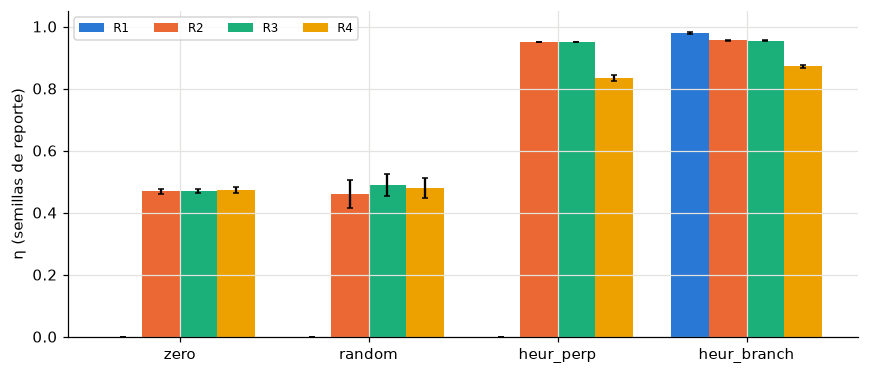

In [16]:
fig, ax = plt.subplots(figsize=(8, 3.5))
ancho = 0.2
for i, nivel in enumerate(NIVELES):
    b = baseline[baseline["nivel"] == nivel].set_index("politica").loc[POLITICAS]
    x = np.arange(len(POLITICAS)) + (i - 1.5) * ancho
    ax.bar(x, b["eta"], ancho, color=NIVEL_COLOR[nivel], label=nivel,
           yerr=[b["eta"] - b["eta_lo"], b["eta_hi"] - b["eta"]], capsize=2)
ax.set_xticks(range(len(POLITICAS)), POLITICAS)
ax.set_ylabel("η (semillas de reporte)")
ax.set_ylim(0, 1.05)
ax.legend(ncol=4, fontsize=8, loc="upper left")
fig.tight_layout()
fig.savefig(FIGURAS / "fig13_parcial_baseline.png", bbox_inches="tight")
plt.show()

Recordando:

$$\eta = \frac{N_{\text{obj}}}{N}$$

donde $N_{\text{obj}}$ es el número de partículas que salieron por el extremo de la rama objetivo y $N = 200$ es el tamaño del enjambre. Vale 0 si no llega ninguna partícula y 1 si llegan todas.

Alineación de la recompensa con η en cada nivel (parte de la hipótesis H1, umbral 0.9):

In [17]:
alineacion = baseline_episodios.groupby("nivel").apply(lambda g: spearman(g["retorno"], g["eta"]))
alineacion.rename("Spearman retorno–η").to_frame().T.round(3)

nivel,R1,R2,R3,R4
Spearman retorno–η,0.812,0.86,0.865,0.997


### 4.4 Variantes

Una **ablación** cambia un solo componente y deja todo lo demás igual (mismas semillas y métrica), para atribuirle a ese componente la diferencia. El proyecto tiene tres grupos de variantes; sus resultados se muestran en la sección 6.

| Grupo | Variantes | Qué se cambia | Sprint |
|---|---|---|---|
| Entorno | Baseline v0.1 → Var1 → Var2 → Var3 | Una corrección del simulador por variante, acumulativas | 2 |
| Observación (features) | base (11) → + margen (12) → − fase (9) | Qué variables ve el agente | 3–4 |
| Hiperparámetros | Configuración inicial frente a 60 configuraciones de la búsqueda aleatoria | Hiperparámetros de PPO | 5 |

Variantes del entorno, con sus parámetros explícitos (lo que no aparece es igual a la variante anterior):

In [18]:
FISICA_V01 = {**FISICA, "pulse_amplitude": 0.5, "pulse_period": 4.0, "particle_radius": 0.0}
RECOMPENSA_V01 = {"progress": 1.0, "target": 1.0, "other": 1.0, "effort": 0.0005}

VARIANTES_ENTORNO = {
    "baseline": {"cambio": "Entorno v0.1 (Sprint 1)", "fisica": FISICA_V01, "recompensa": RECOMPENSA_V01},
    "var1": {"cambio": "Recompensa corregida", "fisica": FISICA_V01, "recompensa": RECOMPENSA},
    "var2": {"cambio": "+ radio de partícula a = 0.05 W", "fisica": {**FISICA_V01, "particle_radius": 0.05},
             "recompensa": RECOMPENSA},
    "var3": {"cambio": "+ pulso fuerte y lento (A = 0.9, T = 20)", "fisica": FISICA, "recompensa": RECOMPENSA},
}

# Comprobación contra el código del proyecto
for nombre, v in VARIANTES_ENTORNO.items():
    assert dataclasses.asdict(VARIANTS[nombre].physics) == v["fisica"]
    assert dataclasses.asdict(VARIANTS[nombre].reward) == v["recompensa"]

pd.DataFrame({n: {"cambio": v["cambio"], **{k: v["fisica"][k] for k in ("pulse_amplitude", "pulse_period", "particle_radius")},
                  **{f"w_{k}": x for k, x in v["recompensa"].items()}}
              for n, v in VARIANTES_ENTORNO.items()}).T.astype(object)

,cambio,pulse_amplitude,pulse_period,particle_radius,w_progress,w_target,w_other,w_effort
baseline,Entorno v0.1 (Sprint 1),0.5,4.0,0.0,1.0,1.0,1.0,0.001
var1,Recompensa corregida,0.5,4.0,0.0,0.1,1.0,0.5,0.0
var2,+ radio de partícula a = 0.05 W,0.5,4.0,0.05,0.1,1.0,0.5,0.0
var3,"+ pulso fuerte y lento (A = 0.9, T = 20)",0.9,20.0,0.05,0.1,1.0,0.5,0.0


Conjuntos de features (variantes de la observación):

In [19]:
CONJUNTOS_FEATURES = {
    "base": NOMBRES_OBS,                                               # las 11 del entorno
    "margen": NOMBRES_OBS + ["control_margin"],                        # + F_max / (F_max + U(t))
    "sin_fase": [n for n in NOMBRES_OBS if n not in ("phase_sin", "phase_cos")],   # − fase del pulso
}
CONJUNTO_ELEGIDO = "sin_fase"   # decisión del Sprint 4
{n: len(v) for n, v in CONJUNTOS_FEATURES.items()}

{'base': 11, 'margen': 12, 'sin_fase': 9}

### 4.5 Modelo: PPO

PPO (Stable-Baselines3) necesita un entorno de Gymnasium. La celda siguiente envuelve el simulador de la sección 3, elige el conjunto de features y comprueba que da las mismas observaciones que el entorno del proyecto.

In [20]:
import gymnasium as gym
from gymnasium import spaces

from nanoswarm.envs.features import FeatureSet


def margen_control(nivel, tiempo):
    # F_max / (F_max + U(t)): 1 sin flujo (manda la fuerza), cerca de 0 con flujo rápido (manda el flujo)
    f = FISICA["v_mag"]
    return f / (f + velocidad_centro(nivel, tiempo))


class EntornoGym(gym.Env):
    def __init__(self, nivel, conjunto=CONJUNTO_ELEGIDO):
        self.base = EntornoEnjambre(nivel)
        self.nombres = CONJUNTOS_FEATURES[conjunto]
        self.columnas = [NOMBRES_OBS.index(n) for n in self.nombres if n in NOMBRES_OBS]
        self.action_space = spaces.Box(-1.0, 1.0, shape=(2,), dtype=np.float32)
        self.observation_space = spaces.Box(-np.inf, np.inf, shape=(len(self.nombres),), dtype=np.float32)

    def _features(self, obs):
        extra = [margen_control(self.base.nivel, self.base.tiempo)] if "control_margin" in self.nombres else []
        return np.concatenate([obs[self.columnas], np.asarray(extra, dtype=np.float32)]).astype(np.float32)

    def reset(self, *, seed=None, options=None):
        super().reset(seed=seed)    # Gymnasium crea self.np_random con la semilla
        return self._features(self.base.reset(rng=self.np_random)), {}

    def step(self, accion):
        obs, r, terminado, truncado, info = self.base.step(accion)
        return self._features(obs), r, terminado, truncado, info


# Comprobación: misma secuencia de observaciones que el entorno del proyecto, con acciones al azar
rng = np.random.default_rng(0)
for conjunto in CONJUNTOS_FEATURES:
    ours, suyo = EntornoGym("R4", conjunto), FeatureSet(make_env(var3, "R4"), conjunto)
    o1, _ = ours.reset(seed=123)
    o2, _ = suyo.reset(seed=123)
    for _ in range(200):
        a = rng.uniform(-1, 1, 2)
        o1, *_ = ours.step(a)
        o2, *_ = suyo.step(a)
        assert np.array_equal(o1, o2)
print("El envoltorio de Gymnasium da las mismas observaciones que el del proyecto en los 3 conjuntos.")

El envoltorio de Gymnasium da las mismas observaciones que el del proyecto en los 3 conjuntos.


Código de entrenamiento. Igual que en el proyecto:

- 4 entornos en paralelo;
- observación normalizada con `VecNormalize`, con media y desviación calculadas solo en entrenamiento;
- la semilla de PPO se pasa tal cual (1000, 1001 o 1002); Stable-Baselines3 fija el primer episodio de cada entorno en semilla + 0…3, y el código lo comprueba;
- se guardan el modelo, las estadísticas de normalización, la curva de aprendizaje y la configuración.

Entrenar una corrida toma de 20 a 50 min, así que aquí no se ejecuta: la sección 6 lee las corridas ya guardadas en `experiments/`.

In [21]:
from stable_baselines3 import PPO
from stable_baselines3.common.callbacks import BaseCallback
from stable_baselines3.common.vec_env import DummyVecEnv, VecNormalize

N_ENTORNOS = 4
PPO_CONTROL = {"learning_rate": 3e-4, "n_steps": 512, "batch_size": 256, "n_epochs": 10,
               "gamma": 0.995, "ent_coef": 0.0, "gae_lambda": 0.95}   # configuración de los Sprints 3–5


class CurvaAprendizaje(BaseCallback):
    # Guarda (pasos acumulados, η) de cada episodio de entrenamiento que termina
    def __init__(self):
        super().__init__()
        self.filas = []

    def _on_step(self):
        for terminado, info in zip(self.locals["dones"], self.locals["infos"]):
            if terminado:
                self.filas.append((self.num_timesteps, info["eta"]))
        return True


def crear_ppo(nivel, conjunto, semilla_ppo, hp=PPO_CONTROL):
    venv = VecNormalize(DummyVecEnv([lambda: EntornoGym(nivel, conjunto) for _ in range(N_ENTORNOS)]),
                        norm_obs=True, norm_reward=False, clip_obs=10.0)
    modelo = PPO("MlpPolicy", venv, seed=semilla_ppo, verbose=0, device="cpu", **hp)
    # PPO(seed=s) fija el primer episodio de cada entorno en s + i; se comprueba antes de entrenar
    assert list(modelo.get_env().venv._seeds) == [semilla_ppo + i for i in range(N_ENTORNOS)]
    return modelo


def entrenar_ppo(nivel, conjunto, semilla_ppo, pasos, carpeta, hp=PPO_CONTROL):
    carpeta = Path(carpeta)
    carpeta.mkdir(parents=True, exist_ok=True)
    modelo = crear_ppo(nivel, conjunto, semilla_ppo, hp)
    curva = CurvaAprendizaje()
    t0 = time.time()
    modelo.learn(total_timesteps=pasos, callback=curva)
    modelo.save(carpeta / "model.zip")
    rms = modelo.get_env().obs_rms
    np.savez(carpeta / "obs_rms.npz", mean=rms.mean, var=rms.var)
    pd.DataFrame(curva.filas, columns=["timestep", "eta"]).to_csv(carpeta / "curve.csv", index=False)
    meta = {"feature_set": conjunto, "condition": nivel, "semilla_ppo": semilla_ppo,
            "semillas_entornos": [semilla_ppo + i for i in range(N_ENTORNOS)],
            "train_seconds": time.time() - t0, "config": {"timesteps": pasos, **hp}, **run_metadata()}
    (carpeta / "meta.json").write_text(json.dumps(meta, indent=2, ensure_ascii=False), encoding="utf-8")
    return meta


# Solo se construye el modelo (sin entrenar) para comprobar que el código funciona
modelo_prueba = crear_ppo("R3", CONJUNTO_ELEGIDO, SEMILLAS_PPO[0])
print(modelo_prueba.policy)

ActorCriticPolicy(
  (features_extractor): FlattenExtractor(
    (flatten): Flatten(start_dim=1, end_dim=-1)
  )
  (pi_features_extractor): FlattenExtractor(
    (flatten): Flatten(start_dim=1, end_dim=-1)
  )
  (vf_features_extractor): FlattenExtractor(
    (flatten): Flatten(start_dim=1, end_dim=-1)
  )
  (mlp_extractor): MlpExtractor(
    (policy_net): Sequential(
      (0): Linear(in_features=9, out_features=64, bias=True)
      (1): Tanh()
      (2): Linear(in_features=64, out_features=64, bias=True)
      (3): Tanh()
    )
    (value_net): Sequential(
      (0): Linear(in_features=9, out_features=64, bias=True)
      (1): Tanh()
      (2): Linear(in_features=64, out_features=64, bias=True)
      (3): Tanh()
    )
  )
  (action_net): Linear(in_features=64, out_features=2, bias=True)
  (value_net): Linear(in_features=64, out_features=1, bias=True)
)


### 4.6 Espacio de hiperparámetros

La búsqueda del Sprint 5 está configurada en `configs/train/search.yaml` (el `config.yaml` de la clase). Seis hiperparámetros de PPO y para hacer eficiente el tiempo se opta por búsqueda aleatoria de 60 trials sin poda y la configuración inicial como referencia. Pues podemos notar que>

Si se supone que el muestreo es uniforme e independiente, que es exactamente lo que hace `RandomSampler`, la probabilidad de que un trial caiga en esa zona es $q$, y la de que no caiga es $1 - q$. Como los trials son independientes, la probabilidad de que ninguno de los $n$ caiga en ella es el producto: $(1 - q)^n$. Por lo tanto, la probabilidad de que **al menos uno** caiga en la zona buena es

$$P(n) = 1 - (1 - q)^n$$

Para que esa probabilidad sea al menos $p$:

$$1 - (1 - q)^n \ge p \;\Longleftrightarrow\; (1 - q)^n \le 1 - p \;\Longleftrightarrow\; n \ge \frac{\ln(1 - p)}{\ln(1 - q)}$$

Con $q = 0.05$ y $p = 0.95$ entonces $n \ge \dfrac{\ln 0.05}{\ln 0.95} = \dfrac{-2.996}{-0.0513} \approx 58.4$, es decir, 60 trials.

| Trials ($n$) | $P$(al menos uno en el 5 % mejor) | Trials esperados en el 5 % mejor ($n\,q$) | Trials en el 10 % superior que usa PED-ANOVA |
|---|---|---|---|
| 20 | $1 - 0.95^{20} = 0.64$ | 1 | 2 |
| 60 | $1 - 0.95^{60} = 0.95$ | 3 | 6 |
| 100 | $1 - 0.95^{100} = 0.99$ | 5 | 10 |

60 es un número justificado para lo que decides con la búsqueda, pero no alcanza para todo.

In [60]:
import yaml

with open(ROOT / "configs" / "train" / "search.yaml", encoding="utf-8") as f:
    BUSQUEDA = yaml.safe_load(f)

ESPACIO = BUSQUEDA["espacio"]
assert {k: BUSQUEDA["control"][k] for k in ESPACIO} == {k: PPO_CONTROL[k] for k in ESPACIO}
pd.DataFrame([{"hiperparámetro": n,
               "rango": (f"[{p['min']:g}, {p['max']:g}], escala log" if p["tipo"] == "float"
                         else "{" + ", ".join(map(str, p["valores"])) + "}"),
               "configuracion inicial": str(PPO_CONTROL[n])} for n, p in ESPACIO.items()]).set_index("hiperparámetro")

,rango,configuracion inicial
hiperparámetro,,
learning_rate,"[0.0001, 0.001], escala log",0.0003
n_steps,"{256, 512, 1024}",512
batch_size,"{64, 128, 256}",256
n_epochs,"{5, 10, 20}",10
gamma,"{0.99, 0.995, 0.999}",0.995
ent_coef,"[1e-05, 0.01], escala log",0.0


In [61]:
b, o = BUSQUEDA["busqueda"], BUSQUEDA["objetivo"]
pd.Series({
    "Trials": b["trials_por_busqueda"],
    "Sampler": f"{b['sampler']} (semillas {BUSQUEDA['semillas']['sampler']}, una por proceso)",
    "Poda": "sin poda" if b["poda"] is None else b["poda"]["pruner"],
    "Presupuesto por trial": f"{o['pasos_por_nivel']:,} pasos × {len(o['niveles'])} niveles",
    "Semilla de PPO": f"{BUSQUEDA['semillas']['ppo']} (entornos {BUSQUEDA['semillas']['entornos_entrenamiento']})",
    "Evaluación": f"cada {o['evaluar_cada']:,} pasos, semillas de ajuste {BUSQUEDA['semillas']['evaluacion']}",
    "Métrica": "eficiencia muestral (η medio de la curva), promedio de los 4 niveles",
    "Regla de decisión": f"reemplaza a la configuracion inicial si mejora ≥ {BUSQUEDA['decision']['mejora_minima']}",
}, name="valor").to_frame()

,valor
Trials,60
Sampler,"RandomSampler (semillas [100, 101, 102, 103, 1..."
Poda,sin poda
Presupuesto por trial,"100,000 pasos × 4 niveles"
Semilla de PPO,"1000 (entornos [1000, 1001, 1002, 1003])"
Evaluación,"cada 10,000 pasos, semillas de ajuste [5000, 5..."
Métrica,"eficiencia muestral (η medio de la curva), pro..."
Regla de decisión,reemplaza a la configuracion inicial si mejora...


## 5. Ingeniería de atributos

### 5.1 Atributos construidos

El simulador conoce la posición de las 200 partículas, pero el agente no las ve: ve un resumen del enjambre. Los atributos son la decisión de qué resumen darle.

| Atributo | Cómo se construye | Por qué |
|---|---|---|
| Centroide (x, y) | Posición media de las partículas activas, **relativa a la bifurcación** | Dónde está el enjambre respecto del punto de decisión, sin depender de dónde está el origen |
| Dispersión (x, y) | Desviación estándar de las posiciones activas | Qué tan abierto está el enjambre (el browniano lo abre en R4) |
| Fracciones | Entregada, perdida y activa; suman 1 | Cuánto del enjambre ya salió y por dónde |
| Fase del pulso | sen(2πt/T) y cos(2πt/T) | Codificación cíclica: el instante del latido, sin el salto de 2π a 0 |
| Acción previa (x, y) | La fuerza del paso anterior | Memoria de un paso de lo que hizo el agente |
| Margen de control | F_max / (F_max + U(t)) | Atributo **derivado del dominio**: cuánto manda la fuerza frente al flujo (1 sin flujo, cerca de 0 con flujo rápido) |

Con ellos se armaron tres conjuntos (sección 4.4): `base` (11), `margen` (12) y `sin_fase` (9). Lo que se sabía de los Sprints 3–4, con PPO entrenado en R3:

- En R3 los tres conjuntos rinden igual (η ≈ 0.97).
- Fuera de R3 no: con `margen`, η en R1 cae a 0; con `base`, solo 1 de 3 semillas funciona en R1; con `sin_fase`, η en R1 es 0.97 en las 3. El margen y la fase toman en R1 valores que la política nunca vio al entrenar.
- Por eso se eligió `sin_fase`.

**Qué se hace mejor ahora.** En el Sprint 4, la importancia por permutación se midió solo en R3 (donde se entrenó) y en R1. Aquí se mide en **los cuatro niveles**, que es lo que pide la hipótesis H4: la importancia de cada variable **fuera** del nivel de entrenamiento.

### 5.2 Corridas que se analizan

Las 9 corridas de PPO de los Sprints 3–4: 3 conjuntos × 3 semillas de PPO, entrenadas en R3 con 300 000 pasos. Aquí no se entrena: se cargan los modelos guardados.

In [24]:
# Las carpetas conservan el nombre de los Sprints 3–4 (s0, s1, s2); la semilla real de PPO está en meta.json
CORRIDAS = {}
filas = []
for conjunto in CONJUNTOS_FEATURES:
    for i, semilla_ppo in enumerate(SEMILLAS_PPO):
        carpeta = ROOT / "experiments" / "pilot" / f"{conjunto}_R3_s{i}"
        meta = json.loads((carpeta / "meta.json").read_text(encoding="utf-8"))
        assert meta["feature_set"] == conjunto and meta["train_seed"] == semilla_ppo and meta["condition"] == "R3"
        CORRIDAS[(conjunto, semilla_ppo)] = carpeta
        filas.append({"conjunto": conjunto, "semilla_ppo": semilla_ppo, "nivel de entrenamiento": meta["condition"],
                      "pasos": meta["config"]["timesteps"], "minutos": meta["train_seconds"] / 60,
                      "carpeta": carpeta.relative_to(ROOT).as_posix()})
pd.DataFrame(filas)

,conjunto,semilla_ppo,nivel de entrenamiento,pasos,minutos,carpeta
0,base,1000,R3,300000,19.195,experiments/pilot/base_R3_s0
1,base,1001,R3,300000,19.081,experiments/pilot/base_R3_s1
2,base,1002,R3,300000,19.161,experiments/pilot/base_R3_s2
3,margen,1000,R3,300000,19.215,experiments/pilot/margen_R3_s0
4,margen,1001,R3,300000,19.338,experiments/pilot/margen_R3_s1
5,margen,1002,R3,300000,19.189,experiments/pilot/margen_R3_s2
6,sin_fase,1000,R3,300000,19.212,experiments/pilot/sin_fase_R3_s0
7,sin_fase,1001,R3,300000,19.126,experiments/pilot/sin_fase_R3_s1
8,sin_fase,1002,R3,300000,15.906,experiments/pilot/sin_fase_R3_s2


Una política guardada se usa congelada: normaliza la observación con la media y la desviación del entrenamiento (`obs_rms.npz`) y elige la acción de forma determinista.

In [25]:
import torch


def cargar_politica(carpeta):
    modelo = PPO.load(Path(carpeta) / "model.zip", device="cpu")
    rms = np.load(Path(carpeta) / "obs_rms.npz")
    media, desv = rms["mean"], np.sqrt(rms["var"] + 1e-8)

    def politica(obs):
        z = np.clip((obs - media) / desv, -10.0, 10.0)    # normalización congelada del entrenamiento
        return modelo.predict(z, deterministic=True)[0]
    return politica


def correr_politica(politica, env, semilla, permutar=None):
    # permutar = (columnas, banco): en cada paso, esas columnas se reemplazan por las de una fila al azar del banco
    rng = np.random.default_rng(semilla + 777) if permutar else None   # reemplazos reproducibles por episodio

    def ver(obs):
        if permutar is None:
            return obs
        columnas, banco = permutar
        obs = obs.copy()
        obs[columnas] = banco[rng.integers(len(banco))][columnas]
        return obs

    obs, _ = env.reset(seed=semilla)
    obs = ver(obs)
    observaciones, terminado, truncado = [], False, False
    while not (terminado or truncado):
        observaciones.append(obs)
        obs, _, terminado, truncado, info = env.step(politica(obs))
        obs = ver(obs)
    return {"eta": info["eta"], "pasos": info["steps"], "obs": np.array(observaciones)}

### 5.3 Importancia por permutación en los cuatro niveles

En RL no hay un conjunto de validación fijo, así que la permutación se hace mientras corre el episodio. En cada paso, las columnas de un grupo de atributos se reemplazan por las de una observación al azar del **banco**: observaciones reales de la misma política en su nivel de entrenamiento (R3). Así se rompe la relación del atributo con el estado sin sacarlo de su rango normal.

**Importancia = η original − η permutado**, comparando episodio a episodio con las mismas semillas. Si es positiva, la política usa ese atributo para decidir. Si es negativa, la política rinde mejor sin él, es decir, ese atributo la confunde en ese nivel.

Los atributos que codifican una misma cantidad se permutan juntos: las tres fracciones suman 1, y seno y coseno son un solo ángulo.

In [26]:
GRUPOS = {
    "centroide_x": ["centroid_x"],
    "centroide_y": ["centroid_y"],
    "dispersion_x": ["spread_x"],
    "dispersion_y": ["spread_y"],
    "fracciones": ["frac_target", "frac_other", "frac_active"],   # suman 1
    "fase": ["phase_sin", "phase_cos"],                            # un solo ángulo
    "accion_previa_x": ["prev_action_x"],
    "accion_previa_y": ["prev_action_y"],
    "margen_control": ["control_margin"],
}

# Semillas, escritas tal cual se usan
SEMILLAS_BANCO = list(range(5_500, 5_510))       # 10 episodios en R3 para el banco; distintas de las de evaluación
SEMILLAS_IMPORTANCIA = SEMILLAS["ajuste"]        # 5000–5019: la importancia sirve para decidir, no se usan las de reporte
assert not set(SEMILLAS_BANCO) & set(SEMILLAS_IMPORTANCIA)


def grupos_de(conjunto):
    # Grupos presentes en un conjunto, con el índice de sus columnas en la observación
    nombres = CONJUNTOS_FEATURES[conjunto]
    return {g: [nombres.index(c) for c in cols] for g, cols in GRUPOS.items() if all(c in nombres for c in cols)}


{c: list(grupos_de(c)) for c in CONJUNTOS_FEATURES}

{'base': ['centroide_x',
  'centroide_y',
  'dispersion_x',
  'dispersion_y',
  'fracciones',
  'fase',
  'accion_previa_x',
  'accion_previa_y'],
 'margen': ['centroide_x',
  'centroide_y',
  'dispersion_x',
  'dispersion_y',
  'fracciones',
  'fase',
  'accion_previa_x',
  'accion_previa_y',
  'margen_control'],
 'sin_fase': ['centroide_x',
  'centroide_y',
  'dispersion_x',
  'dispersion_y',
  'fracciones',
  'accion_previa_x',
  'accion_previa_y']}

Cada tarea es una corrida en un nivel: η original y η con cada grupo permutado, con las 20 semillas de ajuste. Son 9 corridas × 4 niveles = 36 tareas y unos 13 000 episodios. Se reparten en los núcleos de la PC con `joblib`, y cada tarea carga su propio modelo.

**Costo:** ~20–25 min con 8 núcleos. Si la búsqueda de hiperparámetros está corriendo, conviene esperar a que termine, porque las dos compiten por la CPU.

In [27]:
from joblib import Parallel, delayed


def tarea_banco(conjunto, semilla_ppo):
    torch.set_num_threads(1)
    politica = cargar_politica(CORRIDAS[(conjunto, semilla_ppo)])
    env = EntornoGym("R3", conjunto)                     # nivel de entrenamiento
    return np.concatenate([correr_politica(politica, env, s)["obs"] for s in SEMILLAS_BANCO])


def tarea_importancia(conjunto, semilla_ppo, nivel, banco):
    torch.set_num_threads(1)
    politica = cargar_politica(CORRIDAS[(conjunto, semilla_ppo)])
    filas = []
    for grupo, columnas in {"original": None, **grupos_de(conjunto)}.items():
        env = EntornoGym(nivel, conjunto)
        for s in SEMILLAS_IMPORTANCIA:
            r = correr_politica(politica, env, s, None if columnas is None else (columnas, banco))
            filas.append({"conjunto": conjunto, "semilla_ppo": semilla_ppo, "nivel": nivel, "grupo": grupo,
                          "semilla_ep": s, "eta": r["eta"]})
    return filas


t0 = time.time()
bancos = dict(zip(CORRIDAS, Parallel(n_jobs=-1)(delayed(tarea_banco)(*k) for k in CORRIDAS)))
print(f"Bancos: {sum(len(b) for b in bancos.values()):,} observaciones en {time.time() - t0:.0f} s")

tareas = [(c, s, nivel) for (c, s) in CORRIDAS for nivel in NIVELES]
resultados = Parallel(n_jobs=-1)(delayed(tarea_importancia)(c, s, nivel, bancos[(c, s)]) for c, s, nivel in tareas)
permutacion = pd.DataFrame([f for filas in resultados for f in filas])
permutacion.to_csv(TABLAS / "parcial_importancia_episodios.csv", index=False)
print(f"{len(permutacion):,} episodios en {(time.time() - t0) / 60:.1f} min")

Bancos: 13,870 observaciones en 36 s
6,480 episodios en 23.9 min


**Reproducibilidad:** en R3 y R1, los episodios tienen que coincidir con los del Sprint 4 (`results/tables/sprint4_episodios_permutacion.csv`), que usaba `semilla_entren` 0–2 para las semillas de PPO 1000–1002.

In [28]:
sprint4 = pd.read_csv(TABLAS / "sprint4_episodios_permutacion.csv")
sprint4["semilla_ppo"] = SEMILLAS_PPO[0] + sprint4["semilla_entren"]
cruce = permutacion.merge(sprint4.rename(columns={"feature_set": "conjunto", "condicion": "nivel"}),
                          on=["conjunto", "semilla_ppo", "nivel", "grupo", "semilla_ep"], suffixes=("", "_sprint4"))
print(f"Episodios comparados con el Sprint 4: {len(cruce):,} (niveles {sorted(cruce['nivel'].unique())})")
print("Diferencia máxima de η:", (cruce["eta"] - cruce["eta_sprint4"]).abs().max())

Episodios comparados con el Sprint 4: 3,240 (niveles ['R1', 'R3'])
Diferencia máxima de η: 0.0


η sin permutar de cada corrida en cada nivel (media de las 20 semillas de ajuste). Cada fila es una semilla de PPO, es decir, un "fold":

In [29]:
original = permutacion[permutacion["grupo"] == "original"]
original.pivot_table(index=["conjunto", "semilla_ppo"], columns="nivel", values="eta").round(3)

nivel                    R1     R2     R3     R4
conjunto semilla_ppo                            
base     1000         0.971  0.952  0.970  0.914
         1001         0.028  0.761  0.966  0.902
         1002         0.000  0.956  0.954  0.849
margen   1000         0.000  0.955  0.969  0.895
         1001         0.000  0.949  0.969  0.887
         1002         0.000  0.963  0.962  0.898
sin_fase 1000         0.965  0.971  0.975  0.868
         1001         0.970  0.953  0.962  0.880
         1002         0.972  0.953  0.960  0.871

In [30]:
# Importancia por episodio (pareada por semilla), luego media por corrida, y media ± desv. entre las 3 semillas de PPO
base_eta = original.set_index(["conjunto", "semilla_ppo", "nivel", "semilla_ep"])["eta"]
perm = permutacion[permutacion["grupo"] != "original"].copy()
perm["eta_original"] = base_eta.loc[list(zip(perm["conjunto"], perm["semilla_ppo"], perm["nivel"], perm["semilla_ep"]))].to_numpy()
perm["importancia"] = perm["eta_original"] - perm["eta"]

por_corrida = perm.groupby(["conjunto", "semilla_ppo", "nivel", "grupo"], as_index=False)["importancia"].mean()
importancia = (por_corrida.groupby(["conjunto", "nivel", "grupo"])["importancia"]
               .agg(media="mean", desv="std").reset_index())
importancia.to_csv(TABLAS / "parcial_importancia.csv", index=False)
importancia.pivot_table(index="grupo", columns=["conjunto", "nivel"], values="media").round(3)

conjunto          base                      margen                       \
nivel               R1     R2     R3     R4     R1     R2     R3     R4   
grupo                                                                     
accion_previa_x -0.362 -0.012 -0.004  0.003  0.000  0.155  0.002  0.000   
accion_previa_y -0.224 -0.067  0.002  0.000  0.000  0.061  0.002 -0.006   
centroide_x      0.333 -0.007  0.003 -0.018  0.000  0.161 -0.007 -0.002   
centroide_y      0.010  0.026  0.145  0.065  0.000  0.012  0.005 -0.004   
dispersion_x    -0.027 -0.064  0.007  0.008  0.000 -0.001  0.012  0.007   
dispersion_y    -0.281 -0.065  0.019  0.038  0.000 -0.010 -0.004  0.015   
fase            -0.312 -0.065  0.053  0.014 -0.320  0.018  0.239  0.044   
fracciones       0.007  0.119  0.159  0.102  0.000  0.150  0.041  0.027   
margen_control     NaN    NaN    NaN    NaN -0.322  0.158 -0.003 -0.010   

conjunto        sin_fase                       
nivel                 R1     R2     R3     R4  
grupo                                          
accion_previa_x    0.000 -0.000  0.000  0.000  
accion_previa_y   -0.001  0.000  0.005  0.006  
centroide_x       -0.005  0.015  0.051 -0.011  
centroide_y        0.001 -0.002  0.086  0.053  
dispersion_x       0.321  0.004  0.018  0.003  
dispersion_y       0.000  0.000  0.012  0.023  
fase                 NaN    NaN    NaN    NaN  
fracciones        -0.003  0.180  0.317  0.173  
margen_control       NaN    NaN    NaN    NaN

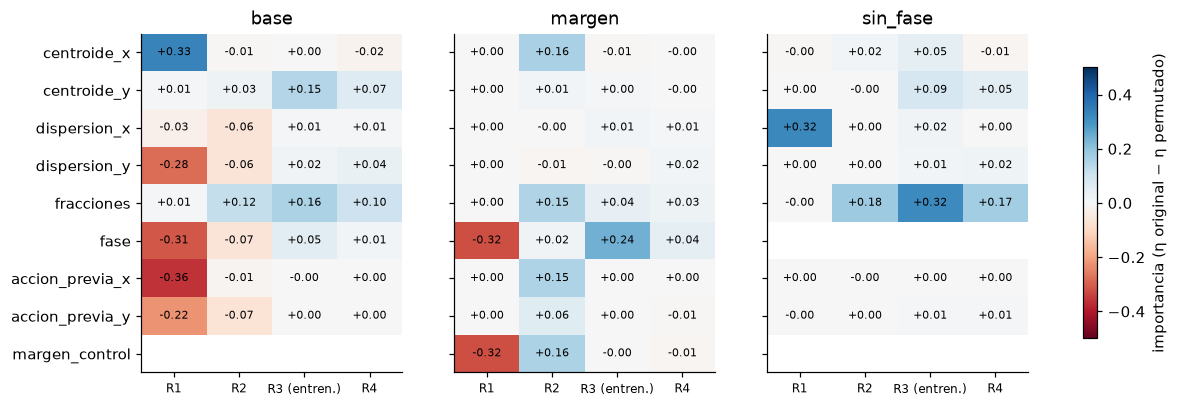

In [31]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4), sharey=True)
orden = list(GRUPOS)
for ax, conjunto in zip(axes, CONJUNTOS_FEATURES):
    t = (importancia[importancia["conjunto"] == conjunto]
         .pivot(index="grupo", columns="nivel", values="media").reindex(orden)[list(NIVELES)])
    im = ax.imshow(t.to_numpy(), cmap="RdBu", vmin=-0.5, vmax=0.5, aspect="auto")
    for (i, j), v in np.ndenumerate(t.to_numpy()):
        if not np.isnan(v):
            ax.text(j, i, f"{v:+.2f}", ha="center", va="center", fontsize=7)
    ax.set_xticks(range(len(NIVELES)), [f"{n}{' (entren.)' if n == 'R3' else ''}" for n in NIVELES], fontsize=8)
    ax.set_title(conjunto)
    ax.grid(False)
axes[0].set_yticks(range(len(orden)), orden)
fig.colorbar(im, ax=axes, shrink=0.8, label="importancia (η original − η permutado)")
fig.savefig(FIGURAS / "fig14_parcial_importancia_4niveles.png", bbox_inches="tight")
plt.show()

Prueba de la hipótesis H4: grupos con importancia ≤ −0.05 **fuera** del nivel de entrenamiento (R1, R2 y R4), es decir, atributos que confunden a la política cuando cambia la física.

In [32]:
UMBRAL_H4 = -0.05
fuera = importancia[(importancia["nivel"] != "R3") & (importancia["media"] <= UMBRAL_H4)]
fuera.sort_values("media").round(3)

,conjunto,nivel,grupo,media,desv
0,base,R1,accion_previa_x,-0.362,0.524
40,margen,R1,margen_control,-0.322,0.551
38,margen,R1,fase,-0.320,0.555
6,base,R1,fase,-0.312,0.540
5,base,R1,dispersion_y,-0.281,0.488
1,base,R1,accion_previa_y,-0.224,0.380
9,base,R2,accion_previa_y,-0.067,0.114
14,base,R2,fase,-0.065,0.110
13,base,R2,dispersion_y,-0.065,0.113
12,base,R2,dispersion_x,-0.064,0.108


**Lectura**

Dentro del nivel de entrenamiento, cada conjunto se apoya en variables distintas. La política sin_fase depende sobre todo de las fracciones del enjambre que ya llegaron a cada rama (0.317) y, en menor medida, de la posición del centroide (0.086 en y, 0.051 en x). La del conjunto base reparte el peso entre las fracciones (0.159) y el centroide en y (0.145), y usa algo la fase (0.053). La del conjunto margen, en cambio, se apoya sobre todo en la fase (0.239): es la que más depende de una variable que solo tiene sentido en los niveles con pulso.

Fuera de R3 aparece lo que buscaba H4. Las importancias negativas, que significan que al desordenar la variable la política funciona mejor, se concentran en R1. Con el conjunto base, la acción previa (−0.362 en x y −0.224 en y), la fase (−0.312) y la dispersión en y (−0.281) confunden a la política cuando desaparece el flujo; con el conjunto margen, la fase y el propio margen de control llegan a −0.32. En R2 el efecto es pequeño y solo aparece con base (entre −0.064 y −0.067), y en R4 ninguna variable baja de −0.02. La política sin_fase no tiene ninguna importancia negativa en ningún nivel: en R1 pasa a apoyarse en la dispersión en x (0.321), y en R2 y R4 sigue usando las fracciones como en R3.

Lo que agrega este análisis frente al del Sprint 4, que solo miraba R3 y R1, es que el problema de los atributos es específico de R1. R2 y R4 cambian la física de entrenamiento casi sin confundir a la política, mientras que R1, donde no hay flujo y la fase del pulso no corresponde a nada físico, es donde las variables dependientes del nivel la llevan a fallar. Hay que leer estas cifras con cuidado: la desviación entre folds es grande en R1 (alrededor de 0.5 con base), porque el efecto solo aparece en los folds cuya política falla en ese nivel. Aun así, el patrón es consistente con la ablación de la sección 6.3.2 y respalda la decisión de usar el conjunto sin_fase.

## 6. Resultados de la validación y ablaciones

### 6.1 Búsqueda de hiperparámetros (60 trials): código completo

**Para correrla:** ejecutar las secciones 0–4 (unos 5 min; la sección 5 no hace falta) y luego la celda siguiente. Tarda unas 6 h con los 8 núcleos al 100 %.

Si se interrumpe, se vuelve a correr la misma celda: retoma desde `journal.log` sin perder los trials terminados. Si ya están los 60, no entrena y solo arma la tabla.

**Para ver el avance mientras corre** (la celda no imprime nada hasta terminar): en una terminal de PowerShell, desde la carpeta del proyecto, cuenta los trials terminados (los que ya tienen `meta.json`):

```powershell
(Get-ChildItem experiments\hpo\random -Recurse -Filter meta.json).Count
```

**Qué es un trial:** una configuración de los 6 hiperparámetros. Se entrenan 4 PPO, uno por nivel, con 100 000 pasos cada uno, en tramos de 10 000. Después de cada tramo se mide η en su propio nivel con las semillas de evaluación. La nota del trial es la **eficiencia muestral**: el η medio de las 10 evaluaciones, promediado en los 4 niveles.

Usa el simulador (sección 3), `EntornoGym` y `crear_ppo` (4.5) y la configuración de `search.yaml` (4.6). Sin poda: en la versión 1, la nota parcial no ordenaba a los trials como la final hasta la 8.ª evaluación.

In [33]:
import optuna
import torch
from joblib import Parallel, delayed

optuna.logging.set_verbosity(optuna.logging.WARNING)

# ---------- Configuración (configs/train/search.yaml, cargado en 4.6) ----------
SEMILLA_PPO = BUSQUEDA["semillas"]["ppo"]                       # 1000: igual en todos los trials y niveles
SEMILLAS_ENTORNOS = BUSQUEDA["semillas"]["entornos_entrenamiento"]   # 1000–1003: primer episodio de cada entorno
SEMILLAS_EVALUACION = BUSQUEDA["semillas"]["evaluacion"]        # 5000–5004: partición de ajuste
SEMILLAS_SAMPLER = BUSQUEDA["semillas"]["sampler"]              # 100–107: una por proceso
N_TRIALS = BUSQUEDA["busqueda"]["trials_por_busqueda"]          # 60
N_PROCESOS = BUSQUEDA["busqueda"]["trials_en_paralelo"]         # 8
PASOS_POR_NIVEL = BUSQUEDA["objetivo"]["pasos_por_nivel"]       # 100 000
EVALUAR_CADA = BUSQUEDA["objetivo"]["evaluar_cada"]             # 10 000 → 10 evaluaciones
GAE_LAMBDA = BUSQUEDA["fijo"]["gae_lambda"]                     # 0.95, fijo
CARPETA_HPO = ROOT / "experiments" / "hpo" / "random"

assert BUSQUEDA["busqueda"]["poda"] is None
assert SEMILLAS_ENTORNOS == [SEMILLA_PPO + i for i in range(N_ENTORNOS)]
assert not set(SEMILLAS_EVALUACION) & set(SEMILLAS["reporte"])
assert N_PROCESOS <= len(SEMILLAS_SAMPLER)


def sugerir(trial):
    # Optuna sortea un valor por hiperparámetro dentro del espacio del yaml
    hp = {}
    for nombre, p in ESPACIO.items():
        if p["tipo"] == "categorico":
            hp[nombre] = trial.suggest_categorical(nombre, p["valores"])
        else:
            hp[nombre] = trial.suggest_float(nombre, p["min"], p["max"], log=p["log"])
    return hp


def evaluar(modelo, nivel):
    # η medio en las semillas de evaluación, con la normalización del entrenamiento congelada y acción determinista
    rms = modelo.get_env().obs_rms
    media, desv = rms.mean.copy(), np.sqrt(rms.var + 1e-8)
    env = EntornoGym(nivel, CONJUNTO_ELEGIDO)
    etas = []
    for semilla in SEMILLAS_EVALUACION:
        obs, _ = env.reset(seed=semilla)
        terminado = truncado = False
        while not (terminado or truncado):
            accion = modelo.predict(np.clip((obs - media) / desv, -10.0, 10.0), deterministic=True)[0]
            obs, _, terminado, truncado, info = env.step(accion)
        etas.append(info["eta"])
    return float(np.mean(etas))


def correr_trial(trial, hp):
    # Un trial: 4 PPO (uno por nivel), entrenados por tramos alternados y evaluados después de cada tramo
    torch.set_num_threads(1)
    carpeta = CARPETA_HPO / f"trial_{trial.number:03d}"
    carpeta.mkdir(parents=True, exist_ok=True)
    hp_ppo = {**hp, "gae_lambda": GAE_LAMBDA}
    modelos = {nivel: crear_ppo(nivel, CONJUNTO_ELEGIDO, SEMILLA_PPO, hp_ppo) for nivel in NIVELES}
    filas, t0 = [], time.time()
    try:
        for k in range(1, PASOS_POR_NIVEL // EVALUAR_CADA + 1):
            for nivel, modelo in modelos.items():
                modelo.learn(total_timesteps=EVALUAR_CADA, reset_num_timesteps=False)
                # PPO completa rollouts enteros: el paso real puede pasar un poco de k × EVALUAR_CADA
                filas.append({"nivel": nivel, "evaluacion": k, "paso": modelo.num_timesteps,
                              "eta": evaluar(modelo, nivel)})
            # Nota parcial: queda registrada en el journal (sin poda)
            trial.report(pd.DataFrame(filas).groupby("nivel")["eta"].mean().mean(), k)
    finally:
        curva = pd.DataFrame(filas)
        curva.to_csv(carpeta / "curve.csv", index=False)
        meta = {"hiperparametros": hp_ppo, "conjunto": CONJUNTO_ELEGIDO, "semilla_ppo": SEMILLA_PPO,
                "semillas_entornos": SEMILLAS_ENTORNOS, "semillas_evaluacion": SEMILLAS_EVALUACION,
                "segundos": time.time() - t0}
        (carpeta / "meta.json").write_text(json.dumps(meta, indent=2), encoding="utf-8")
    return curva


def objetivo(trial):
    hp = sugerir(trial)
    t0 = time.time()
    curva = correr_trial(trial, hp)
    por_nivel = curva.groupby("nivel").agg(eficiencia=("eta", "mean"), eta_final=("eta", "last"))
    for nivel, fila in por_nivel.iterrows():
        trial.set_user_attr(f"eficiencia_{nivel}", float(fila["eficiencia"]))
        trial.set_user_attr(f"eta_final_{nivel}", float(fila["eta_final"]))
    trial.set_user_attr("eficiencia_std", float(por_nivel["eficiencia"].std()))
    trial.set_user_attr("eta_final", float(por_nivel["eta_final"].mean()))
    trial.set_user_attr("segundos", time.time() - t0)
    return float(por_nivel["eficiencia"].mean())       # nota del trial: eficiencia muestral


def abrir_estudio(trabajador=0):
    # Estudio en un journal en disco: lo comparten los 8 procesos y permite retomar
    CARPETA_HPO.mkdir(parents=True, exist_ok=True)
    ruta = str(CARPETA_HPO / "journal.log")
    storage = optuna.storages.JournalStorage(optuna.storages.journal.JournalFileBackend(
        ruta, lock_obj=optuna.storages.journal.JournalFileOpenLock(ruta)))
    return optuna.create_study(storage=storage, study_name="random", direction="maximize",
                               sampler=optuna.samplers.RandomSampler(seed=SEMILLAS_SAMPLER[trabajador]),
                               pruner=optuna.pruners.NopPruner(), load_if_exists=True)


def trabajador(i):
    # Cada proceso toma trials hasta que el estudio llega a N_TRIALS (contando los que están corriendo)
    abrir_estudio(i).optimize(objetivo, callbacks=[optuna.study.MaxTrialsCallback(N_TRIALS, states=None)])


# ---------- Corrida ----------
t0 = time.time()
terminados = sum(t.state.is_finished() for t in abrir_estudio().trials)
print(f"Trials terminados antes de empezar: {terminados} de {N_TRIALS}")
if terminados < N_TRIALS:
    Parallel(n_jobs=N_PROCESOS)(delayed(trabajador)(i) for i in range(N_PROCESOS))

aleatoria = pd.DataFrame([{"trial_id": t.number, "estado": t.state.name, **t.params, "valor": t.value,
                           **t.user_attrs} for t in abrir_estudio().trials])
aleatoria["minutos"] = aleatoria["segundos"] / 60
aleatoria.to_csv(CARPETA_HPO / "trials.csv", index=False)
print(f"{len(aleatoria)} trials; esta celda tardó {(time.time() - t0) / 60:.0f} min")
print(aleatoria["estado"].value_counts().to_string())

c:\Users\Numpy\Documents\tesis\TesisMIA_Magnetic-Nanoswarm_RL\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Trials terminados antes de empezar: 0 de 60
60 trials; esta celda tardó 375 min
estado
COMPLETE    60


### 6.2 Resultados de la búsqueda

Se leen los resultados guardados (`trials.csv` y la configuración inicial), así que **no hace falta volver a correr 6.1**: basta con las secciones 0–4.

La **configuración inicial** es la de los Sprints 3–4 (guardada en `experiments/hpo/control`), medida igual que un trial: mismos 4 niveles, misma semilla de PPO (1000) y mismas semillas de evaluación (5000–5004).

In [34]:
# ---------- Resultados guardados ----------
CARPETA_HPO = ROOT / "experiments" / "hpo" / "random"          # 60 trials (versión 2)
CARPETA_CONTROL = ROOT / "experiments" / "hpo" / "control"     # configuración actual
N_TRIALS = BUSQUEDA["busqueda"]["trials_por_busqueda"]          # 60
HP = list(ESPACIO)                                              # los 6 hiperparámetros buscados

aleatoria = pd.read_csv(CARPETA_HPO / "trials.csv").sort_values("trial_id").reset_index(drop=True)
control = json.loads((CARPETA_CONTROL / "resumen.json").read_text(encoding="utf-8"))
meta_control = json.loads((CARPETA_CONTROL / "meta.json").read_text(encoding="utf-8"))

assert len(aleatoria) == N_TRIALS and (aleatoria["estado"] == "COMPLETE").all()
assert meta_control["hiperparametros"] == BUSQUEDA["control"]
# El control se corrió con el módulo (semilla 0 + base 1000): es la misma semilla de PPO que los trials
assert 1000 + meta_control["fijo"]["semilla_entrenamiento"] == BUSQUEDA["semillas"]["ppo"]

# ---------- Top-5 frente al control ----------
METRICAS = ["valor", "eficiencia_std", "eta_final"] + [f"eficiencia_{n}" for n in NIVELES]
fila_control = {"trial_id": "control", **BUSQUEDA["control"], "valor": control["eficiencia"],
                **{m: control[m] for m in METRICAS[1:]}, "minutos": control["segundos"] / 60}
top5 = aleatoria.sort_values("valor", ascending=False).head(5)
tabla_top = pd.concat([top5, pd.DataFrame([fila_control])])[["trial_id"] + HP + METRICAS + ["minutos"]]
tabla_top["dif_vs_control"] = tabla_top["valor"] - control["eficiencia"]
tabla_top.to_csv(TABLAS / "parcial_hpo_top5.csv", index=False)
tabla_top.round(4)

,trial_id,learning_rate,n_steps,batch_size,n_epochs,gamma,ent_coef,valor,eficiencia_std,eta_final,eficiencia_R1,eficiencia_R2,eficiencia_R3,eficiencia_R4,minutos,dif_vs_control
4,4,1.000e-04,512,64,20,0.990,0.000e+00,0.894,0.066,0.958,0.795,0.924,0.928,0.927,65.595,0.019
13,13,1.000e-04,512,128,20,0.999,9.700e-03,0.886,0.064,0.970,0.800,0.878,0.925,0.943,56.630,0.012
44,44,7.000e-04,256,256,10,0.990,3.000e-04,0.879,0.122,0.691,0.699,0.920,0.972,0.926,36.943,0.004
15,15,3.000e-04,512,64,5,0.995,1.000e-04,0.871,0.052,0.964,0.800,0.894,0.869,0.922,46.942,-0.003
47,47,9.000e-04,512,128,10,0.995,5.000e-04,0.863,0.123,0.960,0.684,0.883,0.961,0.925,41.913,-0.011
0,control,3.000e-04,512,256,10,0.995,0.000e+00,0.875,0.069,0.961,0.800,0.832,0.936,0.931,47.762,0.000


**Regla de decisión** (fijada en `search.yaml` antes de correr): la mejor configuración reemplaza a la configuración inicial solo si mejora la eficiencia muestral en al menos 0.02 **y** su η final no cae más de 0.01.

In [ ]:
DECISION = BUSQUEDA["decision"]
mejor = top5.iloc[0]
mejora = mejor["valor"] - control["eficiencia"]
caida = control["eta_final"] - mejor["eta_final"]
cumple_mejora = mejora >= DECISION["mejora_minima"]
cumple_caida = caida <= DECISION["caida_max_eta_final"]

print(f"Mejor trial: {int(mejor['trial_id'])}  eficiencia {mejor['valor']:.4f}  vs control {control['eficiencia']:.4f}")
print(f"  mejora   {mejora:+.4f}  (mínimo {DECISION['mejora_minima']})  -> {'cumple' if cumple_mejora else 'NO cumple'}")
print(f"  caída η final {caida:+.4f}  (máximo {DECISION['caida_max_eta_final']})  -> {'cumple' if cumple_caida else 'NO cumple'}")
print(f"Decisión: {'se adopta el trial ' + str(int(mejor['trial_id'])) if cumple_mejora and cumple_caida else 'se mantiene la configuracion inicial'}")
print(f"Trials que superan al control: {(aleatoria['valor'] > control['eficiencia']).sum()} de {len(aleatoria)}")

# De dónde sale la diferencia: eficiencia por nivel, mejor trial menos control
pd.Series({n: mejor[f"eficiencia_{n}"] - control[f"eficiencia_{n}"] for n in NIVELES}, name="mejor − control").round(4)

Mejor trial: 4  eficiencia 0.8936  vs control 0.8747
  mejora   +0.0189  (mínimo 0.02)  -> NO cumple
  caída η final +0.0037  (máximo 0.01)  -> cumple
Decisión: se mantiene el control
Trials que superan al control: 3 de 60


R1   -0.005
R2    0.092
R3   -0.008
R4   -0.004
Name: mejor − control, dtype: float64

**Podio top-k con nota de decisión** (formato de la clase): los 5 mejores trials y la configuración inicial, con su costo, su variación entre niveles y por qué están ahí. La nota es mi lectura de cada fila después de ver los resultados.

In [62]:
NOTAS_PODIO = {   # trial_id: nota de decisión, escrita tras revisar la fila
    4: "Mejor eficiencia (+0.019, bajo el umbral de 0.02); la ventaja sale casi toda de R2 y cuesta 37 % más tiempo. Usarlo solo si se confirma con 3 semillas.",
    13: "Segundo (+0.012) y con el η final más alto (0.970); lr bajo y ent_coef alto. Respaldo 1.",
    44: "El más rápido (37 min) pero colapsa en R1 (η final 0.00) y tiene la mayor variación entre niveles. Descartado: incumple la caída de η final.",
    15: "Prácticamente igual al control (−0.003) con la menor variación entre niveles. Respaldo 2.",
    47: "Por debajo del control (−0.011) y con variación alta, por R1. No aporta.",
}
podio = top5.copy()
podio["nota de decisión"] = podio["trial_id"].map(NOTAS_PODIO)
podio["exp_id"] = podio["trial_id"].map(lambda t: f"H-{int(t):03d}")
fila_c = {"exp_id": "H-inicial", "valor": control["eficiencia"], "eficiencia_std": control["eficiencia_std"],
          "eta_final": control["eta_final"], "minutos": control["segundos"] / 60, **BUSQUEDA["control"],
          "nota de decisión": "Configuración de los Sprints 3–4. Se mantiene: ningún trial la supera por el umbral."}
podio = pd.concat([podio, pd.DataFrame([fila_c])], ignore_index=True)
podio["rango"] = list(range(1, len(top5) + 1)) + ["—"]
podio["eficiencia (± entre niveles)"] = podio["valor"].map("{:.3f}".format) + " ± " + podio["eficiencia_std"].map("{:.3f}".format)
podio["resumen hp"] = podio.apply(lambda r: f"lr={r['learning_rate']:.1e}, n_steps={int(r['n_steps'])}, batch={int(r['batch_size'])}, "
                                            f"epochs={int(r['n_epochs'])}, γ={r['gamma']}, ent={r['ent_coef']:.1e}", axis=1)
podio = podio[["rango", "exp_id", "eficiencia (± entre niveles)", "eta_final", "minutos", "resumen hp", "nota de decisión"]]
podio.to_csv(TABLAS / "parcial_hpo_podio.csv", index=False)
with pd.option_context("display.max_colwidth", 120):
    display(podio.round({"eta_final": 3, "minutos": 0}))

,rango,exp_id,eficiencia (± entre niveles),eta_final,minutos,resumen hp,nota de decisión
0,1,H-004,0.894 ± 0.066,0.958,66.0,"lr=1.2e-04, n_steps=512, batch=64, epochs=20, γ=0.99, ent=1.6e-05","Mejor eficiencia (+0.019, bajo el umbral de 0.02); la ventaja sale casi toda de R2 y cuesta 37 % más tiempo. Usarlo ..."
1,2,H-013,0.886 ± 0.064,0.970,57.0,"lr=1.1e-04, n_steps=512, batch=128, epochs=20, γ=0.999, ent=9.7e-03",Segundo (+0.012) y con el η final más alto (0.970); lr bajo y ent_coef alto. Respaldo 1.
2,3,H-044,0.879 ± 0.122,0.690,37.0,"lr=7.5e-04, n_steps=256, batch=256, epochs=10, γ=0.99, ent=2.5e-04",El más rápido (37 min) pero colapsa en R1 (η final 0.00) y tiene la mayor variación entre niveles. Descartado: incum...
3,4,H-015,0.871 ± 0.052,0.964,47.0,"lr=3.5e-04, n_steps=512, batch=64, epochs=5, γ=0.995, ent=5.3e-05",Prácticamente igual al control (−0.003) con la menor variación entre niveles. Respaldo 2.
4,5,H-047,0.863 ± 0.123,0.960,42.0,"lr=9.4e-04, n_steps=512, batch=128, epochs=10, γ=0.995, ent=4.5e-04","Por debajo del control (−0.011) y con variación alta, por R1. No aporta."
5,—,H-inicial,0.875 ± 0.069,0.961,48.0,"lr=3.0e-04, n_steps=512, batch=256, epochs=10, γ=0.995, ent=0.0e+00",Configuración de los Sprints 3–4. Se mantiene: ningún trial la supera por el umbral.


**Evolución de la búsqueda.** Cada punto es un trial, en el orden en que empezó. La línea escalonada es el mejor valor hasta ese trial.

**Regla de parada** (sección 4.6): si el mejor valor no sube más de 0.02 entre los trials 40 y 59, 60 trials bastaron.

Mejor hasta el trial 39: 0.8936; hasta el 59: 0.8936; subida +0.0000 -> 60 trials bastaron


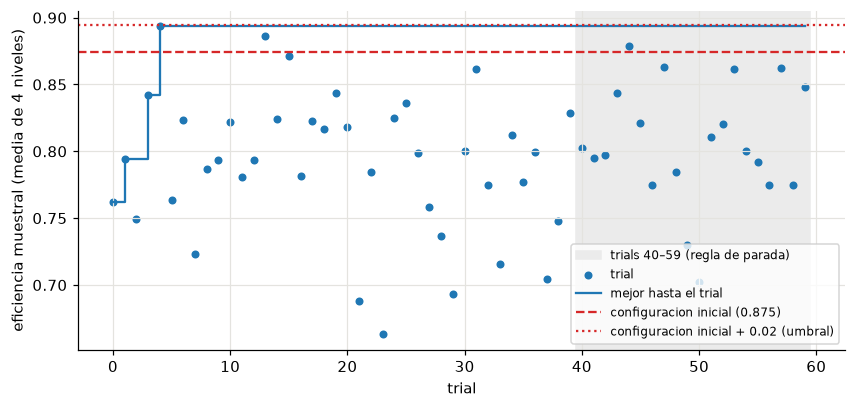

In [63]:
mejor_hasta = aleatoria["valor"].cummax()
subida_40_59 = mejor_hasta.iloc[N_TRIALS - 1] - mejor_hasta.iloc[39]
print(f"Mejor hasta el trial 39: {mejor_hasta.iloc[39]:.4f}; hasta el 59: {mejor_hasta.iloc[N_TRIALS - 1]:.4f}; "
      f"subida {subida_40_59:+.4f} -> {'60 trials bastaron' if subida_40_59 <= 0.02 else 'convendría seguir'}")

fig, ax = plt.subplots(figsize=(9, 4))
ax.axvspan(39.5, N_TRIALS - 0.5, color="0.92", label="trials 40–59 (regla de parada)")
ax.scatter(aleatoria["trial_id"], aleatoria["valor"], s=18, color="C0", label="trial")
ax.step(aleatoria["trial_id"], mejor_hasta, where="post", color="C0", lw=1.5, label="mejor hasta el trial")
ax.axhline(control["eficiencia"], color="C3", ls="--", label=f"configuracion inicial ({control['eficiencia']:.3f})")
ax.axhline(control["eficiencia"] + DECISION["mejora_minima"], color="C3", ls=":", label="configuracion inicial + 0.02 (umbral)")
ax.set_xlabel("trial")
ax.set_ylabel("eficiencia muestral (media de 4 niveles)")
ax.legend(fontsize=8, loc="lower right")
fig.savefig(FIGURAS / "fig15_parcial_hpo_evolucion.png", bbox_inches="tight")
plt.show()

**Importancia de los hiperparámetros.** Se usa PED-ANOVA (Watanabe et al., 2023), que viene con Optuna: mide qué hiperparámetro distingue a los mejores trials (el 10 % superior) del resto. No se usa fANOVA porque necesita scikit-learn, que no está en el entorno.

Junto a ella, el valor medio y máximo de la eficiencia para cada valor de los hiperparámetros categóricos, que es lo que se lee directamente.

In [39]:
import optuna

optuna.logging.set_verbosity(optuna.logging.WARNING)
ruta_journal = str(CARPETA_HPO / "journal.log")
estudio = optuna.load_study(study_name="random", storage=optuna.storages.JournalStorage(
    optuna.storages.journal.JournalFileBackend(ruta_journal,
                                               lock_obj=optuna.storages.journal.JournalFileOpenLock(ruta_journal))))
importancia_hp = pd.Series(optuna.importance.get_param_importances(
    estudio, evaluator=optuna.importance.PedAnovaImportanceEvaluator()), name="importancia")
importancia_hp.to_csv(TABLAS / "parcial_hpo_importancia.csv")
importancia_hp.round(3)

n_steps          0.609
batch_size       0.102
n_epochs         0.100
gamma            0.073
ent_coef         0.068
learning_rate    0.047
Name: importancia, dtype: float64

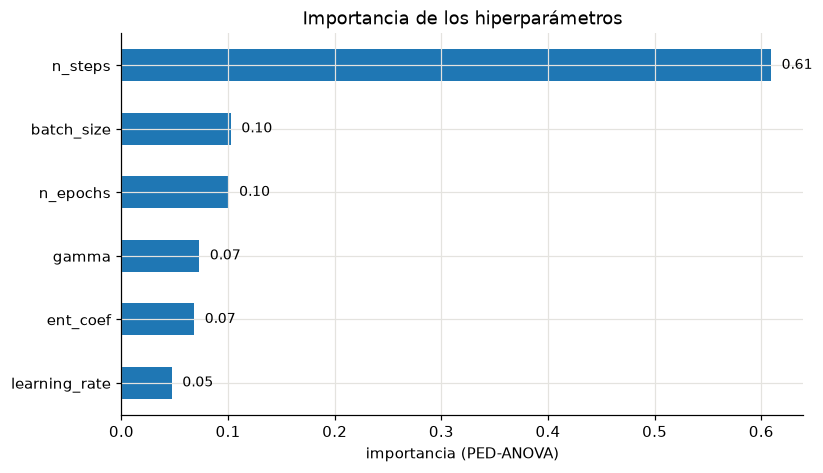

In [40]:
fig, ax = plt.subplots(figsize=(8, 4.5))
importancia_hp.sort_values().plot.barh(ax=ax, color="C0")
for y, v in enumerate(importancia_hp.sort_values()):
    ax.text(v + 0.01, y, f"{v:.2f}", va="center", fontsize=9)
ax.set_xlabel("importancia (PED-ANOVA)")
ax.set_title("Importancia de los hiperparámetros")
fig.savefig(FIGURAS / "fig16a_parcial_hpo_importancia.png", bbox_inches="tight")
plt.show()


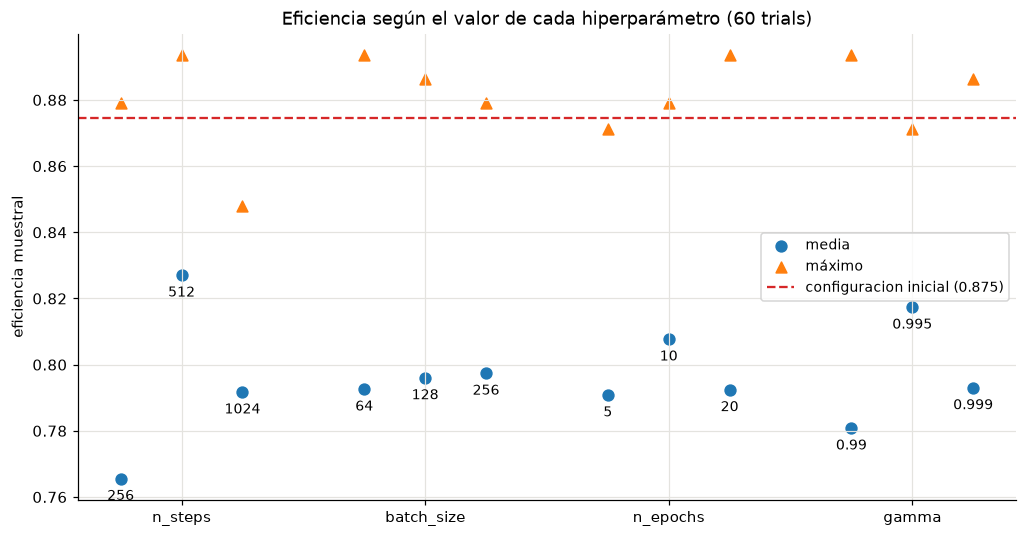

In [64]:
CATEGORICOS = [h for h in HP if ESPACIO[h]["tipo"] == "categorico"]
fig, ax = plt.subplots(figsize=(11, 5.5))
for i, h in enumerate(CATEGORICOS):
    g = aleatoria.groupby(h)["valor"]
    xs = i + np.linspace(-0.25, 0.25, g.ngroups)
    ax.scatter(xs, g.mean(), s=50, color="C0", marker="o", label="media" if i == 0 else None)
    ax.scatter(xs, g.max(), s=50, color="C1", marker="^", label="máximo" if i == 0 else None)
    for x, v in zip(xs, g.mean().index):
        ax.annotate(str(v), (x, g.mean()[v]), textcoords="offset points", xytext=(0, -14), ha="center", fontsize=9)
ax.axhline(control["eficiencia"], color="C3", ls="--", label=f"configuracion inicial ({control['eficiencia']:.3f})")
ax.set_xticks(range(len(CATEGORICOS)), CATEGORICOS, fontsize=10)
ax.set_ylabel("eficiencia muestral")
ax.set_title("Eficiencia según el valor de cada hiperparámetro (60 trials)")
ax.legend(fontsize=9)
fig.savefig(FIGURAS / "fig16b_parcial_hpo_eficiencia_por_valor.png", bbox_inches="tight")
plt.show()


**Slice plot.** Cada punto es un trial: su eficiencia frente al valor que tomó cada hiperparámetro. La línea punteada es el valor de la configuración inicial; el círculo negro, el mejor trial. La importancia (fig. 16a) dice cuánto pesa cada hiperparámetro; esta figura muestra dónde están los buenos valores.

In [ ]:
mejor_t = aleatoria.loc[aleatoria["valor"].idxmax()]
# Mismo eje y en las seis figuras, para que se puedan comparar entre sí
margen_y = 0.02
LIM_Y_SLICE = (aleatoria["valor"].min() - margen_y, aleatoria["valor"].max() + margen_y)


def slice_hp(h):
    # Eficiencia de cada trial frente al valor que tomó el hiperparámetro h
    fig, ax = plt.subplots(figsize=(8, 5))
    ax.scatter(aleatoria[h], aleatoria["valor"], s=36, color="C0", alpha=0.7, label="trial (60)")
    ax.scatter(mejor_t[h], mejor_t["valor"], s=120, facecolors="none", edgecolors="k", lw=1.5,
               label=f"mejor (trial {int(mejor_t['trial_id'])})")
    if BUSQUEDA["control"][h] > 0:                      # ent_coef inicial es 0: no cabe en eje log
        ax.axvline(BUSQUEDA["control"][h], color="0.3", ls="--", lw=1, label="valor de la configuración inicial")
    if ESPACIO[h]["tipo"] == "categorico":
        valores = ESPACIO[h]["valores"]
        if h in ("n_steps", "batch_size", "n_epochs"):
            ax.set_xscale("log", base=2)
        ax.set_xticks(valores, [str(v) for v in valores])
        ax.minorticks_off()
    elif ESPACIO[h]["log"]:
        ax.set_xscale("log")
    ax.set_xlabel(h)
    ax.set_ylabel("eficiencia muestral")
    ax.set_ylim(LIM_Y_SLICE)
    ax.legend(fontsize=9, loc="lower right")
    ax.set_title(f"Eficiencia de cada trial frente a {h} (60 trials)")
    fig.tight_layout()
    fig.savefig(FIGURAS / f"fig17_parcial_hpo_slice_{h}.png", bbox_inches="tight")
    plt.show()


print("Orden de las figuras:", HP)


Orden de las figuras: ['learning_rate', 'n_steps', 'batch_size', 'n_epochs', 'gamma', 'ent_coef']


Eficiencia de cada trial frente a learning rate (60 trials)

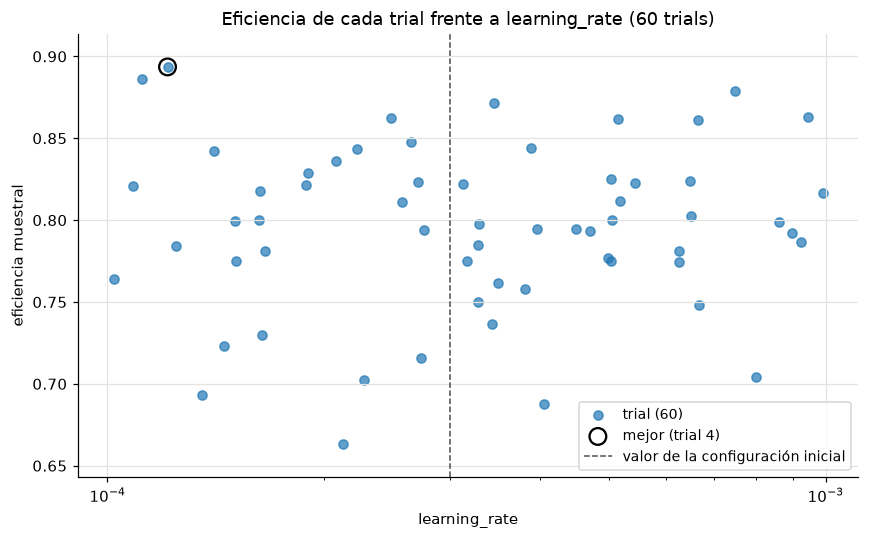

In [68]:
slice_hp(HP[0])

Eficiencia de cada trial frente a número de pasos (60 trials)

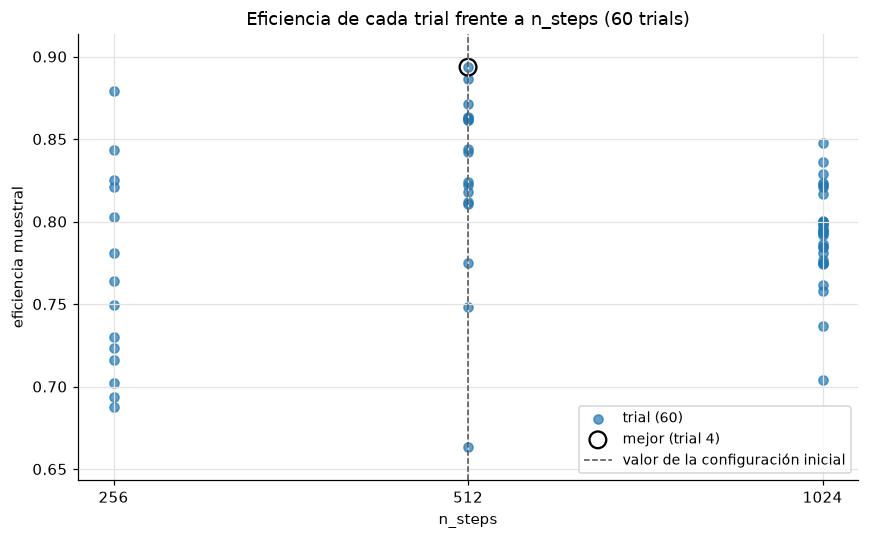

In [69]:
slice_hp(HP[1])

Eficiencia de cada trial frente al tamaño del batch (60 trials)

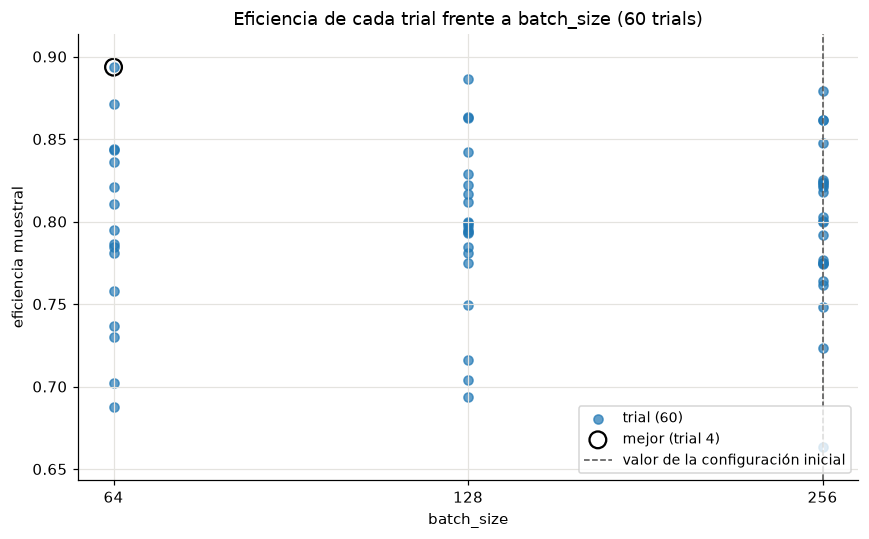

In [70]:
slice_hp(HP[2])

Eficiencia de cada trial frente al número de épocas (60 trials)

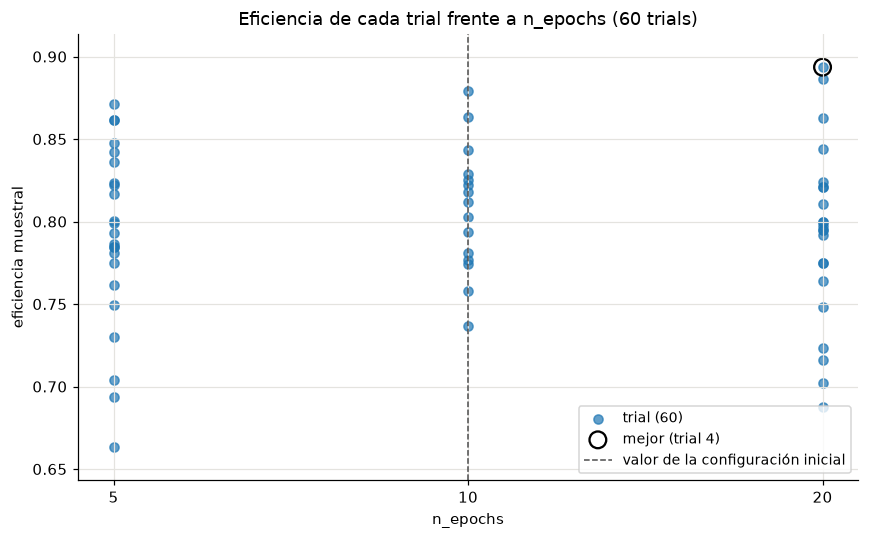

In [71]:
slice_hp(HP[3])

Eficiencia de cada trial frente al parámetro gamma (60 trials)

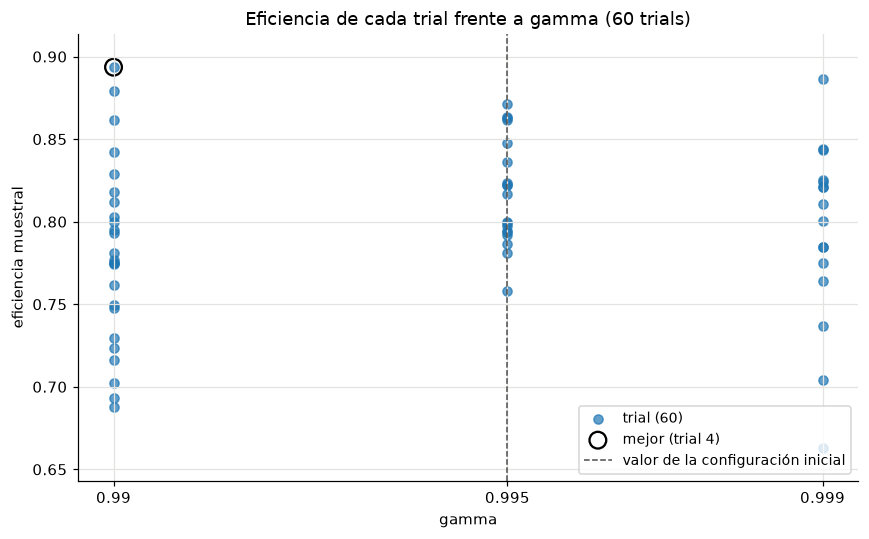

In [72]:
slice_hp(HP[4])

**Costo frente a beneficio.** Minutos que tardó cada trial (con 8 procesos en paralelo) frente a su eficiencia, coloreado por `n_steps`. Sirve para ver si las mejores configuraciones son también las más caras.

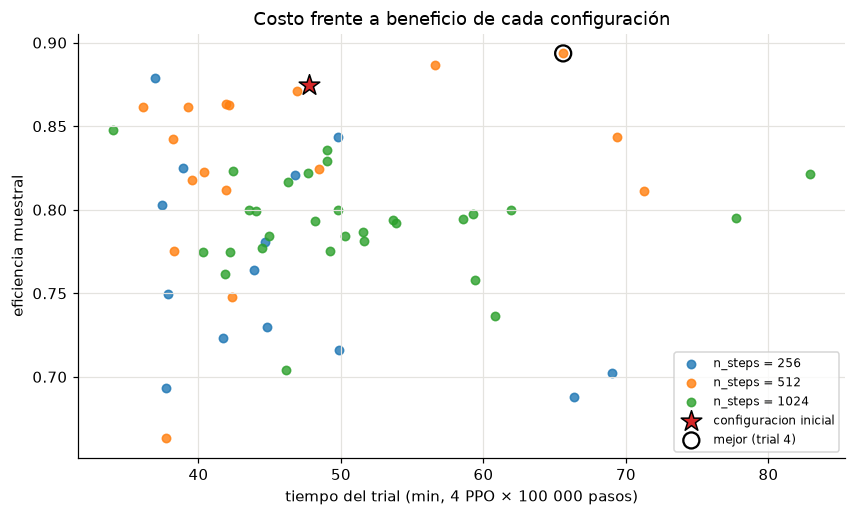

Mejor trial: 66 min; configuracion inicial: 48 min; mediana de los trials: 46 min


In [73]:
fig, ax = plt.subplots(figsize=(9, 5))
for j, v in enumerate(ESPACIO["n_steps"]["valores"]):
    t = aleatoria[aleatoria["n_steps"] == v]
    ax.scatter(t["minutos"], t["valor"], s=30, color=f"C{j}", alpha=0.8, label=f"n_steps = {v}")
ax.scatter(control["segundos"] / 60, control["eficiencia"], s=200, marker="*", color="C3", edgecolors="k",
           zorder=3, label="configuracion inicial")
ax.scatter(mejor_t["minutos"], mejor_t["valor"], s=110, facecolors="none", edgecolors="k", lw=1.5,
           label=f"mejor (trial {int(mejor_t['trial_id'])})")
ax.set_xlabel("tiempo del trial (min, 4 PPO × 100 000 pasos)")
ax.set_ylabel("eficiencia muestral")
ax.set_title("Costo frente a beneficio de cada configuración")
ax.legend(fontsize=8, loc="lower right")
fig.savefig(FIGURAS / "fig21_parcial_hpo_costo_beneficio.png", bbox_inches="tight")
plt.show()
print(f"Mejor trial: {mejor_t['minutos']:.0f} min; configuracion inicial: {control['segundos'] / 60:.0f} min; "
      f"mediana de los trials: {aleatoria['minutos'].median():.0f} min")

**¿Fue correcto no podar?** Ahora que los 60 trials terminaron, se repite la prueba de la versión 1: Spearman entre la nota parcial (media de η hasta la evaluación k, la que se reportaba a Optuna) y la nota final.

In [42]:
from scipy.stats import spearmanr

parciales = []
for t in aleatoria["trial_id"]:
    curva = pd.read_csv(CARPETA_HPO / f"trial_{t:03d}" / "curve.csv")
    por_eval = curva.groupby("evaluacion")["eta"].mean()                 # media de los 4 niveles
    parciales.append(por_eval.cumsum() / np.arange(1, len(por_eval) + 1))  # nota parcial en cada evaluación
parciales = pd.DataFrame(parciales).reset_index(drop=True)
final = parciales.iloc[:, -1]
pd.Series({k: spearmanr(parciales[k], final)[0] for k in parciales.columns},
          name="Spearman(parcial, final)").rename_axis("evaluación").round(2).to_frame().T

evaluación,1,2,3,4,5,6,7,8,9,10
"Spearman(parcial, final)",0.15,0.26,0.32,0.54,0.7,0.83,0.92,0.96,0.98,1.0


**Lectura**

- **Decisión: se mantiene la configuración inicial.** El mejor trial (4) supera a la configuración inicial en +0.019, por debajo del umbral de 0.02, y solo 3 de 60 trials superan a la configuración inicial. La configuración de los Sprints 3–4 ya estaba cerca de lo mejor del espacio.
- **La ventaja del trial 4 sale casi toda de R2** (≈ +0.09). En R1, R3 y R4 queda igual o un poco abajo. Con una sola semilla de PPO, esa diferencia no se distingue del ruido.
- **60 trials bastaron.** El mejor valor apareció en el trial 4 y no subió entre los trials 40 y 59.
- **El hiperparámetro que más pesa es `n_steps`** (≈ 0.6 de la importancia). 512 por entorno, el valor de la configuración inicial, tiene la mejor media. Los demás pesan entre 0.05 y 0.10.
- **No podar fue correcto.** La nota parcial recién ordena a los trials como la final desde la 6.ª–7.ª evaluación (Spearman ≥ 0.83). En la 4.ª–5.ª, donde se habría podado, está entre 0.54 y 0.70.
- **Riesgo encontrado: R1.** En 13 de los 60 trials, la política de R1 termina con η < 0.5 (11 de ellos en 0), mientras que en R2–R4 ninguna cae bajo 0.5. Se analiza en la sección 7.

### 6.3 Resultados por fold y ablaciones

Una ablación cambia **un solo factor** y deja todo lo demás igual. Aquí hay cuatro, todas con corridas que ya existen (no se entrena nada):

| Ablación | Qué cambia | Qué queda fijo | Datos |
|---|---|---|---|
| 6.3.1 Entorno | baseline → Var1 → Var2 → Var3 | políticas heurísticas | Sprint 2, semillas 9000–9029 |
| 6.3.2 Atributos | base (11) / margen (12) / sin_fase (9) | PPO con la configuración inicial, entrenado en R3 | sección 5, semillas de ajuste 5000–5019 |
| 6.3.3 Hiperparámetros | configuración inicial / mejor / mediana / peor trial | entorno Var3, sin_fase | sección 6.2, semillas 5000–5004 |
| Validación (early stopping) | modelo final / mejor checkpoint | los 60 trials en R1 | sección 7.3, semillas 5000–5004 |

Un **fold** es una semilla de PPO (1000, 1001, 1002): misma configuración, distinta inicialización y distinta experiencia. La desviación entre folds mide qué tan estable es el resultado.

#### 6.3.1 Ablación de entorno

Cada variante agrega un cambio sobre la anterior (sección 4.4). Se mide con las dos heurísticas, que no aprenden: así el cambio en η se debe solo al entorno.

Estas tablas son las del Sprint 2, que usó la partición de reporte porque ahí se eligió el entorno; desde entonces el entorno está congelado (v0.2 = Var3).

In [43]:
episodios_entorno = pd.concat([pd.read_csv(TABLAS / f"episodes_sprint2_{v}.csv") for v in VARIANTES_ENTORNO])
assert set(episodios_entorno["seed"]) == set(SEMILLAS["reporte"])

ablacion_entorno = (episodios_entorno[episodios_entorno["policy"].isin(["heur_perp", "heur_branch"])]
                    .pivot_table(index=["policy", "variant"], columns="condition", values="eta")
                    .reindex(list(VARIANTES_ENTORNO), level="variant"))
transito = (episodios_entorno[episodios_entorno["policy"] == "heur_branch"]
            .pivot_table(index="variant", columns="condition", values="transit")
            .reindex(list(VARIANTES_ENTORNO)).add_prefix("tránsito "))
display(ablacion_entorno.round(3))
transito.round(1)

condition                R1     R2     R3     R4
policy      variant                             
heur_branch baseline  0.976  0.952  0.951  0.916
            var1      0.976  0.952  0.951  0.916
            var2      0.980  0.955  0.956  0.918
            var3      0.980  0.955  0.954  0.871
heur_perp   baseline  0.000  0.000  0.000  0.879
            var1      0.000  0.000  0.000  0.879
            var2      0.000  0.950  0.951  0.900
            var3      0.000  0.950  0.950  0.835

condition,tránsito R1,tránsito R2,tránsito R3,tránsito R4
variant,,,,
baseline,31.2,19.6,18.7,11.1
var1,31.2,19.6,18.7,11.1
var2,31.3,13.7,13.2,9.7
var3,31.3,13.7,10.4,6.9


**R2 frente a R3 en el entorno final (Var3).** η y dos métricas secundarias por nivel, con las dos heurísticas. Es la evidencia de la discusión de la sección 8.2.

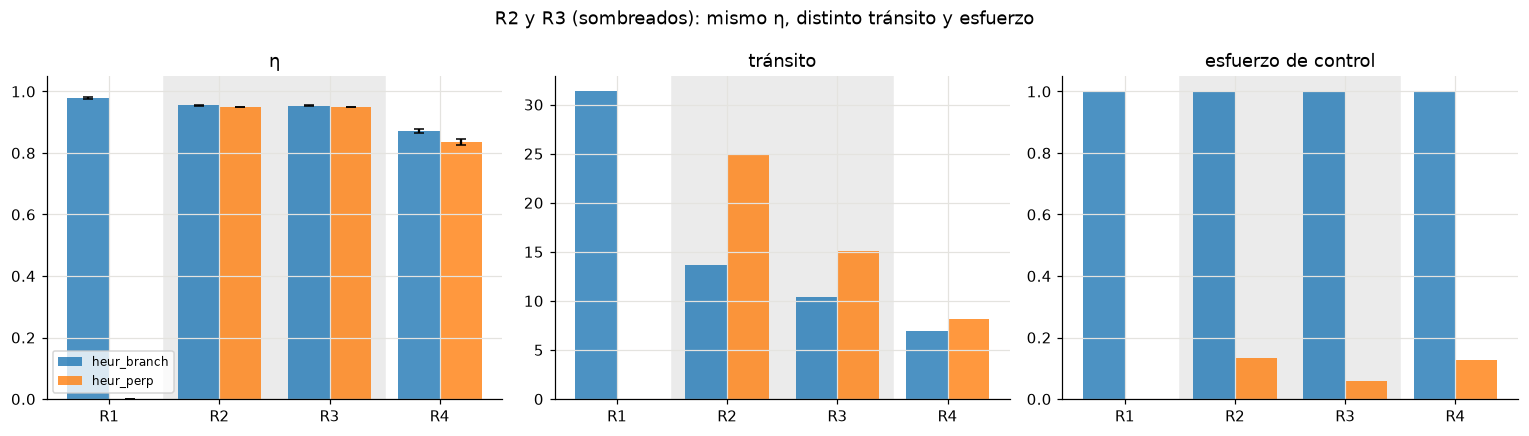

In [55]:
resumen_base = pd.read_csv(TABLAS / "parcial_baseline_resumen.csv")
HEURISTICAS = ["heur_branch", "heur_perp"]
METRICAS_R = {"eta": "η", "transito": "tránsito", "esfuerzo": "esfuerzo de control"}
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, (m, nombre) in zip(axes, METRICAS_R.items()):
    for j, politica in enumerate(HEURISTICAS):
        t = resumen_base[resumen_base["politica"] == politica].set_index("nivel").reindex(list(NIVELES))
        xs = np.arange(len(NIVELES)) + (j - 0.5) * 0.38
        err = None
        if m == "eta":
            err = [t["eta"] - t["eta_lo"], t["eta_hi"] - t["eta"]]
        ax.bar(xs, t[m], width=0.38, color=f"C{j}", alpha=0.8, yerr=err, capsize=3, label=politica)
    ax.axvspan(0.5, 2.5, color="0.92", zorder=0)       # R2 y R3
    ax.set_xticks(range(len(NIVELES)), list(NIVELES))
    ax.set_title(nombre)
axes[0].set_ylim(0, 1.05)
axes[0].legend(fontsize=8, loc="lower left")
fig.suptitle("R2 y R3 (sombreados): mismo η, distinto tránsito y esfuerzo")
fig.tight_layout()
fig.savefig(FIGURAS / "fig23_parcial_R2_R3.png", bbox_inches="tight")
plt.show()

#### 6.3.2 Ablación de atributos, por fold

η de las 9 políticas de la sección 5 (3 conjuntos × 3 folds, entrenadas en R3) sin permutar nada, en los 4 niveles. R3 es el nivel de entrenamiento; los otros tres miden generalización.

In [44]:
episodios_atributos = pd.read_csv(TABLAS / "parcial_importancia_episodios.csv")
originales = episodios_atributos[episodios_atributos["grupo"] == "original"]
assert set(originales["semilla_ep"]) == set(SEMILLAS["ajuste"])

por_fold = originales.pivot_table(index=["conjunto", "semilla_ppo"], columns="nivel", values="eta")[list(NIVELES)]
por_fold.to_csv(TABLAS / "parcial_atributos_por_fold.csv")
por_fold.round(3)

nivel                    R1     R2     R3     R4
conjunto semilla_ppo                            
base     1000         0.971  0.952  0.970  0.914
         1001         0.028  0.761  0.966  0.902
         1002         0.000  0.956  0.954  0.849
margen   1000         0.000  0.955  0.969  0.895
         1001         0.000  0.949  0.969  0.887
         1002         0.000  0.963  0.962  0.898
sin_fase 1000         0.965  0.971  0.975  0.868
         1001         0.970  0.953  0.962  0.880
         1002         0.972  0.953  0.960  0.871

In [45]:
# Media ± desviación entre los 3 folds, y brecha de generalización: η en R3 (entrenamiento) − η en cada nivel
resumen_atributos = por_fold.groupby("conjunto").agg(["mean", "std"])
brecha = por_fold.rsub(por_fold["R3"], axis=0).drop(columns="R3").groupby("conjunto").agg(["mean", "std"])
tabla_atributos = pd.DataFrame({
    **{f"η {n}": resumen_atributos[n]["mean"].map("{:.3f}".format) + " ± " + resumen_atributos[n]["std"].map("{:.3f}".format)
       for n in NIVELES},
    **{f"brecha R3→{n}": brecha[n]["mean"].map("{:+.3f}".format) for n in ["R1", "R2", "R4"]},
    "folds con η R1 < 0.5": por_fold["R1"].lt(0.5).groupby("conjunto").sum(),
}).reindex(list(CONJUNTOS_FEATURES))
tabla_atributos.to_csv(TABLAS / "parcial_atributos_resumen.csv")
tabla_atributos

,η R1,η R2,η R3,η R4,brecha R3→R1,brecha R3→R2,brecha R3→R4,folds con η R1 < 0.5
conjunto,,,,,,,,
base,0.333 ± 0.553,0.890 ± 0.111,0.964 ± 0.008,0.888 ± 0.035,+0.631,+0.074,+0.075,2
margen,0.000 ± 0.000,0.956 ± 0.007,0.967 ± 0.004,0.893 ± 0.006,+0.967,+0.011,+0.073,3
sin_fase,0.969 ± 0.004,0.959 ± 0.010,0.966 ± 0.008,0.873 ± 0.006,-0.004,+0.007,+0.093,0


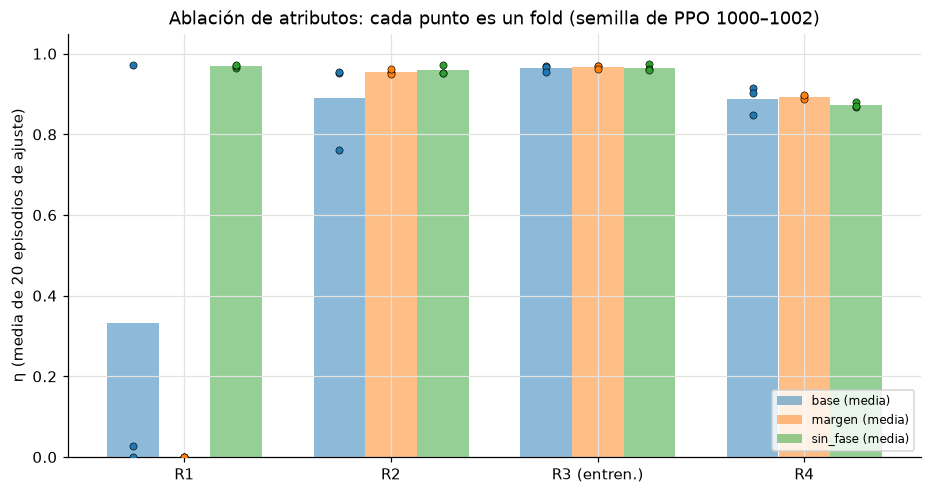

In [46]:
fig, ax = plt.subplots(figsize=(10, 5))
ancho = 0.25
for j, conjunto in enumerate(CONJUNTOS_FEATURES):
    t = por_fold.loc[conjunto]
    xs = np.arange(len(NIVELES)) + (j - 1) * ancho
    ax.bar(xs, t.mean(), width=ancho, color=f"C{j}", alpha=0.5, label=f"{conjunto} (media)")
    for semilla, fila in t.iterrows():
        ax.scatter(xs, fila.to_numpy(), color=f"C{j}", s=22, edgecolors="k", linewidths=0.4, zorder=3)
ax.set_xticks(range(len(NIVELES)), [f"{n}{' (entren.)' if n == 'R3' else ''}" for n in NIVELES])
ax.set_ylabel("η (media de 20 episodios de ajuste)")
ax.set_ylim(0, 1.05)
ax.set_title("Ablación de atributos: cada punto es un fold (semilla de PPO 1000–1002)")
ax.legend(fontsize=8, loc="lower right")
fig.savefig(FIGURAS / "fig18_parcial_atributos_por_fold.png", bbox_inches="tight")
plt.show()

#### 6.3.3 Ablación de hiperparámetros

Mismo entorno, mismos atributos (sin_fase) y misma semilla; solo cambian los 6 hiperparámetros. Se comparan la configuración inicial y tres trials de la búsqueda: el mejor, el de la mediana y el peor. Usa `aleatoria` y `control` de la sección 6.2.

In [47]:
ordenados = aleatoria.sort_values("valor", ascending=False).reset_index(drop=True)
elegidos = {"mejor": ordenados.iloc[0], "mediana": ordenados.iloc[len(ordenados) // 2], "peor": ordenados.iloc[-1]}
filas = [{"configuración": "control", **BUSQUEDA["control"], "eficiencia": control["eficiencia"],
          **{f"eficiencia {n}": control[f"eficiencia_{n}"] for n in NIVELES},
          **{f"η final {n}": control[f"eta_final_{n}"] for n in NIVELES}}]
for nombre, t in elegidos.items():
    filas.append({"configuración": f"{nombre} (trial {int(t['trial_id'])})", **{h: t[h] for h in HP},
                  "eficiencia": t["valor"], **{f"eficiencia {n}": t[f"eficiencia_{n}"] for n in NIVELES},
                  **{f"η final {n}": t[f"eta_final_{n}"] for n in NIVELES}})
ablacion_hp = pd.DataFrame(filas).set_index("configuración")
ablacion_hp.to_csv(TABLAS / "parcial_ablacion_hp.csv")
ablacion_hp.round(4).T

configuración,control,mejor (trial 4),mediana (trial 42),peor (trial 23)
learning_rate,3.000e-04,1.000e-04,3.000e-04,2.000e-04
n_steps,5.120e+02,5.120e+02,1.024e+03,5.120e+02
batch_size,2.560e+02,6.400e+01,1.280e+02,2.560e+02
n_epochs,1.000e+01,2.000e+01,2.000e+01,5.000e+00
gamma,9.950e-01,9.900e-01,9.950e-01,9.990e-01
ent_coef,0.000e+00,0.000e+00,0.000e+00,5.300e-03
eficiencia,8.747e-01,8.936e-01,7.974e-01,6.632e-01
eficiencia R1,7.998e-01,7.949e-01,4.808e-01,4.395e-01
eficiencia R2,8.321e-01,9.242e-01,9.045e-01,5.127e-01
eficiencia R3,9.357e-01,9.280e-01,8.829e-01,7.909e-01


**Curvas de evaluación por nivel.** η en cada una de las 10 evaluaciones para la configuración inicial y los tres trials elegidos. La eficiencia muestral es el área bajo estas curvas; el η final es su último punto.

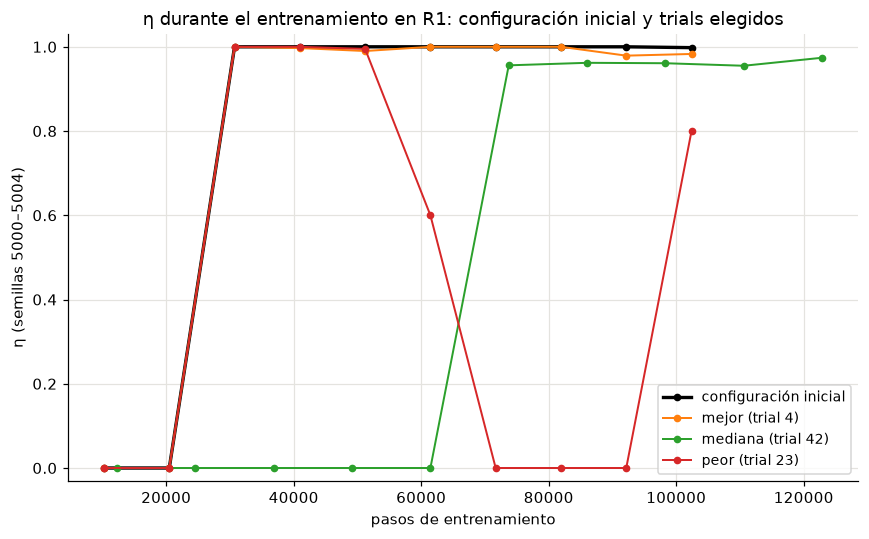

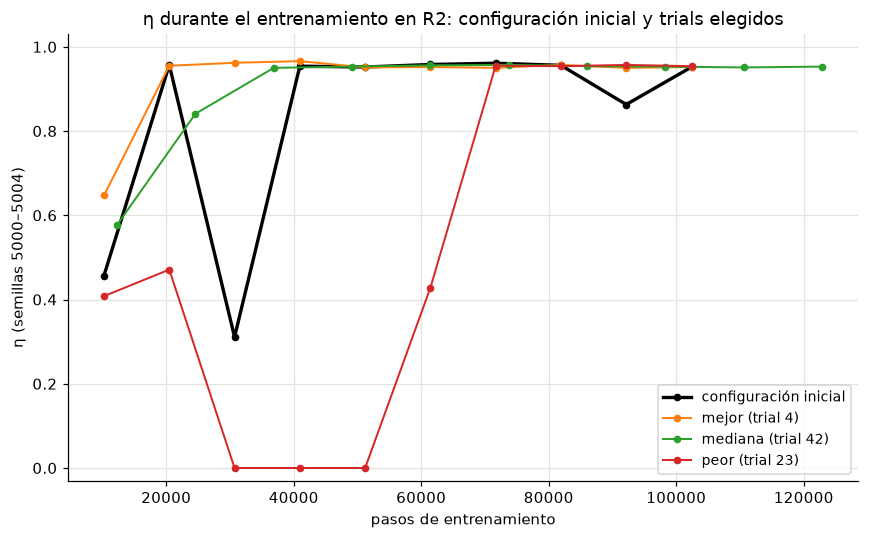

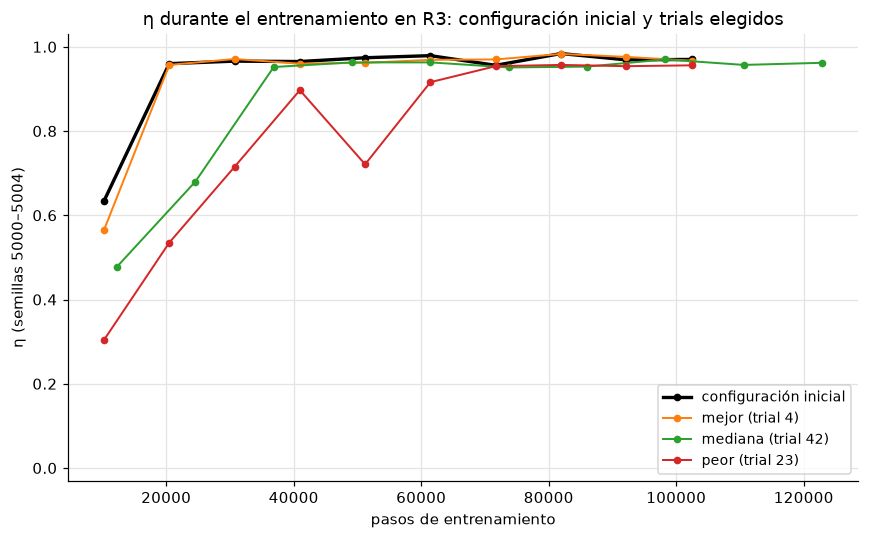

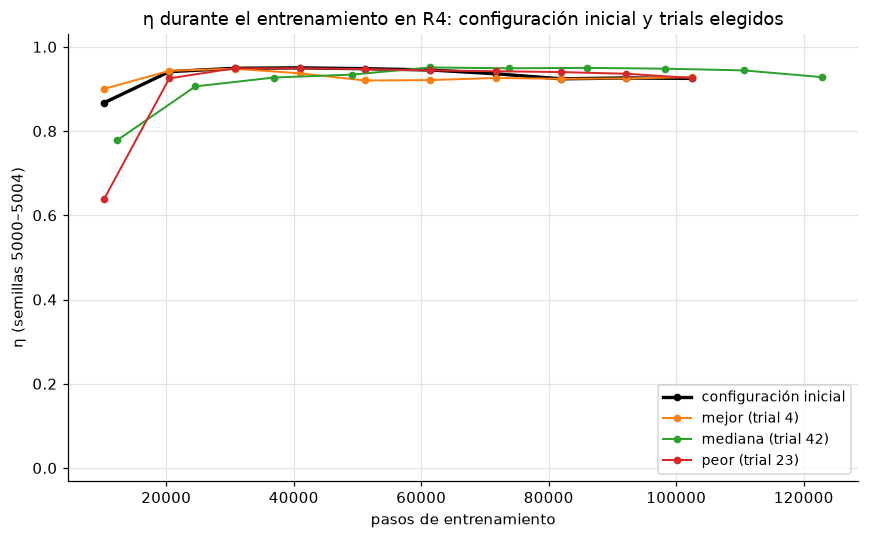

In [74]:
curvas_hp = {"configuración inicial": pd.read_csv(CARPETA_CONTROL / "curve.csv")}
for nombre, t in elegidos.items():
    curvas_hp[f"{nombre} (trial {int(t['trial_id'])})"] = pd.read_csv(
        CARPETA_HPO / f"trial_{int(t['trial_id']):03d}" / "curve.csv")

# Mismo eje y en las cuatro figuras, para que se puedan comparar entre niveles
eta_todas = pd.concat(curvas_hp.values())["eta"]
lim_y = (eta_todas.min() - 0.03, eta_todas.max() + 0.03)

for nivel in NIVELES:
    fig, ax = plt.subplots(figsize=(8, 5))
    for j, (nombre, c) in enumerate(curvas_hp.items()):
        t = c[c["nivel"] == nivel]
        es_inicial = nombre == "configuración inicial"
        ax.plot(t["paso"], t["eta"], marker="o", ms=4, lw=2.2 if es_inicial else 1.3,
                color="k" if es_inicial else f"C{j}", label=nombre)
    ax.set_xlabel("pasos de entrenamiento")
    ax.set_ylabel("η (semillas 5000–5004)")
    ax.set_ylim(lim_y)
    ax.legend(fontsize=9, loc="lower right")
    ax.set_title(f"η durante el entrenamiento en {nivel}: configuración inicial y trials elegidos")
    fig.tight_layout()
    fig.savefig(FIGURAS / f"fig22_parcial_hpo_curvas_{nivel}.png", bbox_inches="tight")
    plt.show()


**Lectura**

| Ablación | Efecto en el nivel de entrenamiento | Efecto fuera de él | Conclusión |
|---|---|---|---|
| Entorno | Var2 (radio de partícula) desbloquea la heurística perpendicular en R2–R3 (η de 0 a 0.95) | Var3 (pulso) separa R4: la mejor heurística baja de 0.918 a 0.871 | Var3 es el primer entorno donde la fidelidad cambia el resultado. R2 y R3 siguen iguales en η, pero ya difieren en tránsito (13.7 vs 10.4 con la heurística de rama), medido con la fase inicial del pulso fija |
| Atributos | Los 3 conjuntos dan η ≈ 0.96–0.97 en R3, con desviación ≤ 0.008 | En R1 cambia todo: base falla en 2 de 3 folds, margen en 3 de 3, sin_fase en ninguno | Quitar la fase es lo que generaliza a R1; la elección del Sprint 4 se sostiene |
| Hiperparámetros | Cada trial se entrena y evalúa en su propio nivel | La eficiencia va de 0.66 (peor) a 0.89 (mejor), sobre todo por R1 y R2; el η final casi no cambia (0.93–0.97 en R2–R4) | Los hiperparámetros cambian la **velocidad** de aprendizaje, no el resultado final |
| Validación (early stopping) | — | Con el mejor checkpoint en vez del modelo final, los trials con η ≥ 0.9 en R1 pasan de 44 a 56 de 60 (sección 7.3; cota optimista) | Es la mitigación más directa del olvido en R1; se incorpora en el siguiente sprint |

- **El riesgo de sobreajuste no se ve en R3, se ve fuera de él.** Dentro de R3 los folds son casi idénticos; en R1 la desviación entre folds llega a 0.55 con base. Una validación solo en el nivel de entrenamiento lo habría ocultado.
- **R1 aparece dos veces como punto frágil:** las políticas entrenadas en R3 con base o margen no lo resuelven, y en la búsqueda, 13 de 60 políticas entrenadas en el propio R1 terminan con η < 0.5. Se analiza en la sección 7 (brecha y mitigación).

## 7. Tablero de corridas y control del sobreajuste

### 7.1 Tablero de corridas

Una fila por corrida, con las columnas que pide la clase (exp_id | modelo | features | hp_resumen | métrica mean±std | tiempo | notas) más la carpeta de artefactos y las semillas, para poder rastrear cada número hasta su origen.

| Prefijo | Corridas | Métrica | ± |
|---|---|---|---|
| B | heurísticas, Var3 (sección 4.3) | η en R3 | entre los 30 episodios de reporte |
| P | PPO entrenado en R3, 3 conjuntos × 3 folds (secciones 5 y 6.3.2) | η en R3 | entre los 3 folds |
| H | configuración inicial y 60 trials (sección 6) | eficiencia muestral | entre los 4 niveles (una sola semilla) |

Se completa con la evolución de la búsqueda (fig. 15) y la importancia de los hiperparámetros (figs. 16a y 16b).

In [48]:
def hp_resumen(hp):
    return (f"lr={hp['learning_rate']:.1e} n_steps={int(hp['n_steps'])} batch={int(hp['batch_size'])} "
            f"epochs={int(hp['n_epochs'])} γ={hp['gamma']} ent={hp['ent_coef']:.1e}")


filas = []

# B: heurísticas (no aprenden)
base_ep = pd.read_csv(TABLAS / "parcial_baseline_episodios.csv")
for politica, t in base_ep[base_ep["nivel"] == "R3"].groupby("politica"):
    filas.append({"exp_id": f"B-{politica}", "modelo": "heurística", "features": "—", "hp_resumen": "—",
                  "métrica": "η R3", "media": t["eta"].mean(), "desv": t["eta"].std(), "tiempo_min": np.nan,
                  "semillas": "episodios 9000–9029", "artefactos": "results/tables/parcial_baseline_episodios.csv",
                  "notas": f"η R1={base_ep[(base_ep['nivel'] == 'R1') & (base_ep['politica'] == politica)]['eta'].mean():.2f}"})

# P: PPO de control entrenado en R3, por conjunto de atributos (3 folds)
for conjunto in CONJUNTOS_FEATURES:
    carpetas = [ROOT / "experiments" / "pilot" / f"{conjunto}_R3_s{i}" for i in range(len(SEMILLAS_PPO))]
    metas = [json.loads((c / "meta.json").read_text(encoding="utf-8")) for c in carpetas]
    assert [m["train_seed"] for m in metas] == SEMILLAS_PPO
    eta_r3 = por_fold.loc[conjunto, "R3"]
    filas.append({"exp_id": f"P-{conjunto}", "modelo": "PPO (300k pasos, R3)", "features": conjunto,
                  "hp_resumen": hp_resumen(BUSQUEDA["control"]), "métrica": "η R3",
                  "media": eta_r3.mean(), "desv": eta_r3.std(),
                  "tiempo_min": np.mean([m["train_seconds"] for m in metas]) / 60,
                  "semillas": f"PPO {SEMILLAS_PPO}; episodios 5000–5019",
                  "artefactos": f"experiments/pilot/{conjunto}_R3_s*",
                  "notas": f"η R1 por fold: {', '.join(f'{v:.2f}' for v in por_fold.loc[conjunto, 'R1'])}"})

# H: control y trials de la búsqueda (4 PPO por fila, uno por nivel)
filas.append({"exp_id": "H-control", "modelo": "PPO ×4 niveles (100k pasos)", "features": CONJUNTO_ELEGIDO,
              "hp_resumen": hp_resumen(BUSQUEDA["control"]), "métrica": "eficiencia",
              "media": control["eficiencia"], "desv": control["eficiencia_std"], "tiempo_min": control["segundos"] / 60,
              "semillas": "PPO 1000; episodios 5000–5004", "artefactos": "experiments/hpo/control",
              "notas": "configuración de los Sprints 3–4; se mantiene"})
for _, t in aleatoria.iterrows():
    notas = []
    if t["trial_id"] == aleatoria.loc[aleatoria["valor"].idxmax(), "trial_id"]:
        notas.append("mejor trial (+0.019, bajo el umbral)")
    if t["eta_final_R1"] < 0.5:
        notas.append(f"colapso en R1 (η final {t['eta_final_R1']:.2f})")
    filas.append({"exp_id": f"H-{int(t['trial_id']):03d}", "modelo": "PPO ×4 niveles (100k pasos)",
                  "features": CONJUNTO_ELEGIDO, "hp_resumen": hp_resumen(t), "métrica": "eficiencia",
                  "media": t["valor"], "desv": t["eficiencia_std"], "tiempo_min": t["minutos"],
                  "semillas": "PPO 1000; episodios 5000–5004",
                  "artefactos": f"experiments/hpo/random/trial_{int(t['trial_id']):03d}", "notas": "; ".join(notas)})

tablero = pd.DataFrame(filas)
tablero["métrica mean±std"] = tablero["media"].map("{:.3f}".format) + " ± " + tablero["desv"].map("{:.3f}".format)
tablero.to_csv(TABLAS / "parcial_tablero.csv", index=False)
print(f"{len(tablero)} corridas en results/tables/parcial_tablero.csv")

# Vista: todo lo que no es trial, más los 5 mejores trials y el peor
COLUMNAS = ["exp_id", "modelo", "features", "hp_resumen", "métrica", "métrica mean±std", "tiempo_min", "notas"]
trials_h = tablero[tablero["exp_id"].str.match(r"H-\d")].sort_values("media", ascending=False)
vista = pd.concat([tablero[~tablero["exp_id"].str.match(r"H-\d")], trials_h.head(5), trials_h.tail(1)])
with pd.option_context("display.max_colwidth", 80):
    display(vista[COLUMNAS].round({"tiempo_min": 1}).reset_index(drop=True))

68 corridas en results/tables/parcial_tablero.csv


,exp_id,modelo,features,hp_resumen,métrica,métrica mean±std,tiempo_min,notas
0,B-heur_branch,heurística,—,—,η R3,0.954 ± 0.004,NaN,η R1=0.98
1,B-heur_perp,heurística,—,—,η R3,0.950 ± 0.001,NaN,η R1=0.00
2,B-random,heurística,—,—,η R3,0.488 ± 0.102,NaN,η R1=0.00
3,B-zero,heurística,—,—,η R3,0.469 ± 0.022,NaN,η R1=0.00
4,P-base,"PPO (300k pasos, R3)",base,lr=3.0e-04 n_steps=512 batch=256 epochs=10 γ=0.995 ent=0.0e+00,η R3,0.964 ± 0.008,19.1,"η R1 por fold: 0.97, 0.03, 0.00"
5,P-margen,"PPO (300k pasos, R3)",margen,lr=3.0e-04 n_steps=512 batch=256 epochs=10 γ=0.995 ent=0.0e+00,η R3,0.967 ± 0.004,19.2,"η R1 por fold: 0.00, 0.00, 0.00"
6,P-sin_fase,"PPO (300k pasos, R3)",sin_fase,lr=3.0e-04 n_steps=512 batch=256 epochs=10 γ=0.995 ent=0.0e+00,η R3,0.966 ± 0.008,18.1,"η R1 por fold: 0.97, 0.97, 0.97"
7,H-control,PPO ×4 niveles (100k pasos),sin_fase,lr=3.0e-04 n_steps=512 batch=256 epochs=10 γ=0.995 ent=0.0e+00,eficiencia,0.875 ± 0.069,47.8,configuración de los Sprints 3–4; se mantiene
8,H-004,PPO ×4 niveles (100k pasos),sin_fase,lr=1.2e-04 n_steps=512 batch=64 epochs=20 γ=0.99 ent=1.6e-05,eficiencia,0.894 ± 0.066,65.6,"mejor trial (+0.019, bajo el umbral)"
9,H-013,PPO ×4 niveles (100k pasos),sin_fase,lr=1.1e-04 n_steps=512 batch=128 epochs=20 γ=0.999 ent=9.7e-03,eficiencia,0.886 ± 0.064,56.6,


### 7.2 Brecha entre entrenamiento y validación

En RL no hay un "train set" fijo: la política genera su propia experiencia. La brecha se mide en tres lugares:

| Brecha | Entrenamiento | Validación | Qué detectaría |
|---|---|---|---|
| (a) Episodios | η de los episodios de entrenamiento (último 10 %, acción estocástica) | η en las semillas de ajuste 5000–5019, mismo nivel R3 | memorizar los episodios vistos |
| (b) Fidelidad | η en R3 | η en R1, R2 y R4 | depender de la física de entrenamiento (la pregunta de la tesis) |
| (c) Tiempo | mejor η alcanzado durante el entrenamiento | η al final | olvidar lo aprendido |

In [49]:
# (a) Brecha de episodios: mismo nivel (R3), episodios de entrenamiento frente a semillas de ajuste
filas = []
for conjunto in CONJUNTOS_FEATURES:
    for i, semilla in enumerate(SEMILLAS_PPO):
        curva = pd.read_csv(ROOT / "experiments" / "pilot" / f"{conjunto}_R3_s{i}" / "curve.csv")
        eta_train = curva.loc[curva["timestep"] >= 0.9 * curva["timestep"].max(), "eta"].mean()
        filas.append({"conjunto": conjunto, "semilla_ppo": semilla, "η entrenamiento (último 10 %)": eta_train,
                      "η validación R3": por_fold.loc[(conjunto, semilla), "R3"]})
brecha_episodios = pd.DataFrame(filas)
brecha_episodios["brecha"] = brecha_episodios["η entrenamiento (último 10 %)"] - brecha_episodios["η validación R3"]
brecha_episodios.to_csv(TABLAS / "parcial_brecha_episodios.csv", index=False)
print(f"Brecha de episodios: media {brecha_episodios['brecha'].mean():+.3f}, "
      f"máxima en valor absoluto {brecha_episodios['brecha'].abs().max():.3f}")
brecha_episodios.round(3)

Brecha de episodios: media -0.003, máxima en valor absoluto 0.010


,conjunto,semilla_ppo,η entrenamiento (último 10 %),η validación R3,brecha
0,base,1000,0.967,0.970,-0.002
1,base,1001,0.968,0.966,0.002
2,base,1002,0.953,0.954,-0.002
3,margen,1000,0.966,0.969,-0.003
4,margen,1001,0.969,0.969,-0.001
5,margen,1002,0.960,0.962,-0.002
6,sin_fase,1000,0.965,0.975,-0.010
7,sin_fase,1001,0.955,0.962,-0.007
8,sin_fase,1002,0.957,0.960,-0.003


**Curva de aprendizaje: entrenamiento frente a validación.** La línea es el η de los episodios de entrenamiento en R3 (media móvil de 50 episodios), una por fold. Al final, los marcadores son el η de validación de esa misma política en cada nivel. Es la señal de sobreajuste de la clase: entrenamiento alto y validación baja. Dentro de R3 no aparece; aparece en R1.

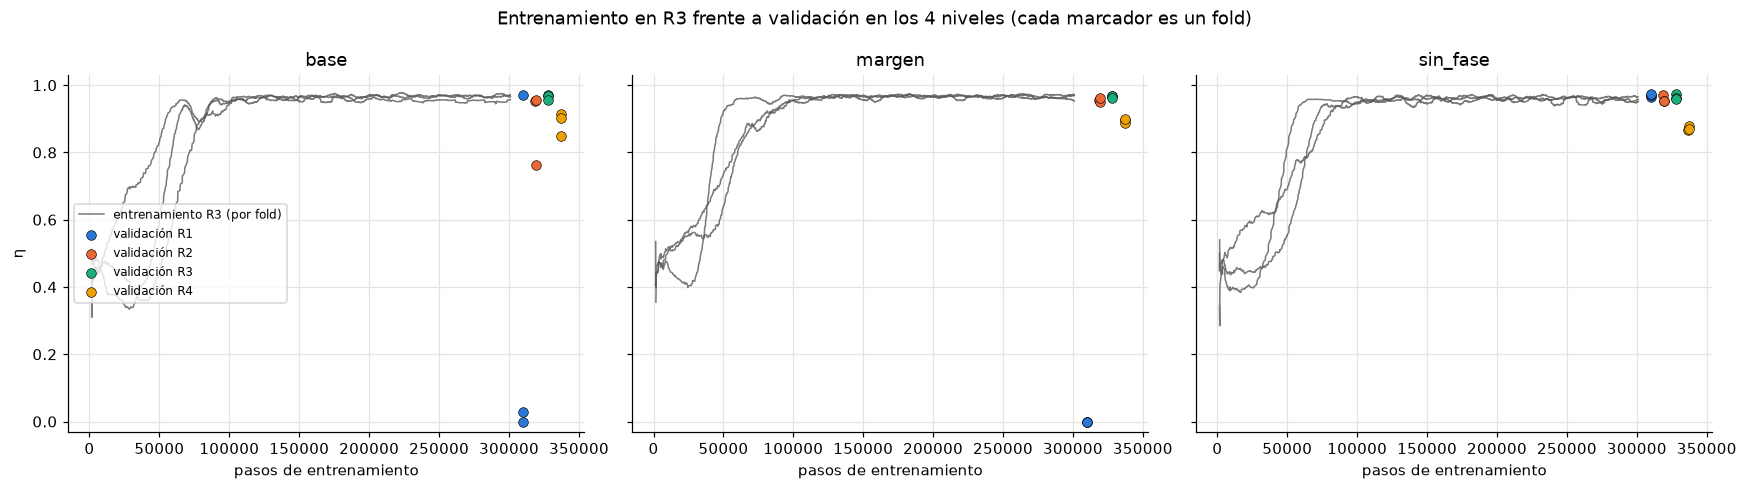

In [53]:
VENTANA = 50          # episodios de la media móvil
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), sharey=True)
for ax, conjunto in zip(axes, CONJUNTOS_FEATURES):
    for i, semilla in enumerate(SEMILLAS_PPO):
        curva = pd.read_csv(ROOT / "experiments" / "pilot" / f"{conjunto}_R3_s{i}" / "curve.csv")
        ax.plot(curva["timestep"], curva["eta"].rolling(VENTANA, min_periods=1).mean(),
                color="0.35", lw=1, alpha=0.8, label="entrenamiento R3 (por fold)" if i == 0 else None)
        x_fin = curva["timestep"].max()
        for k, nivel in enumerate(NIVELES):
            ax.scatter(x_fin * (1.03 + 0.03 * k), por_fold.loc[(conjunto, semilla), nivel], s=40,
                       color=NIVEL_COLOR[nivel], edgecolors="k", linewidths=0.4, zorder=3,
                       label=f"validación {nivel}" if i == 0 else None)
    ax.set_title(conjunto)
    ax.set_xlabel("pasos de entrenamiento")
axes[0].set_ylabel("η")
axes[0].set_ylim(-0.03, 1.03)
axes[0].legend(fontsize=8, loc="center left")
fig.suptitle("Entrenamiento en R3 frente a validación en los 4 niveles (cada marcador es un fold)")
fig.tight_layout()
fig.savefig(FIGURAS / "fig20_parcial_train_vs_val.png", bbox_inches="tight")
plt.show()

In [50]:
# (b) Brecha de fidelidad: η en R3 − η en cada nivel, por fold (tabla de la sección 6.3.2)
brecha_fidelidad = por_fold.rsub(por_fold["R3"], axis=0).drop(columns="R3")
brecha_fidelidad.to_csv(TABLAS / "parcial_brecha_fidelidad.csv")
brecha_fidelidad.round(3)

nivel                    R1     R2     R4
conjunto semilla_ppo                     
base     1000        -0.001  0.017  0.055
         1001         0.939  0.205  0.064
         1002         0.954 -0.001  0.106
margen   1000         0.969  0.014  0.074
         1001         0.969  0.020  0.083
         1002         0.962 -0.001  0.064
sin_fase 1000         0.009  0.004  0.107
         1001        -0.009  0.009  0.082
         1002        -0.012  0.007  0.089

Trials con η final < 0.5 en R1: 13 de 60
  de ellos, llegaron antes a η ≥ 0.9 (aprendieron y olvidaron): 11
  nunca llegaron a 0.9: 2
Caídas de η ≥ 0.9 a < 0.5 entre dos evaluaciones seguidas (todos los trials): 23


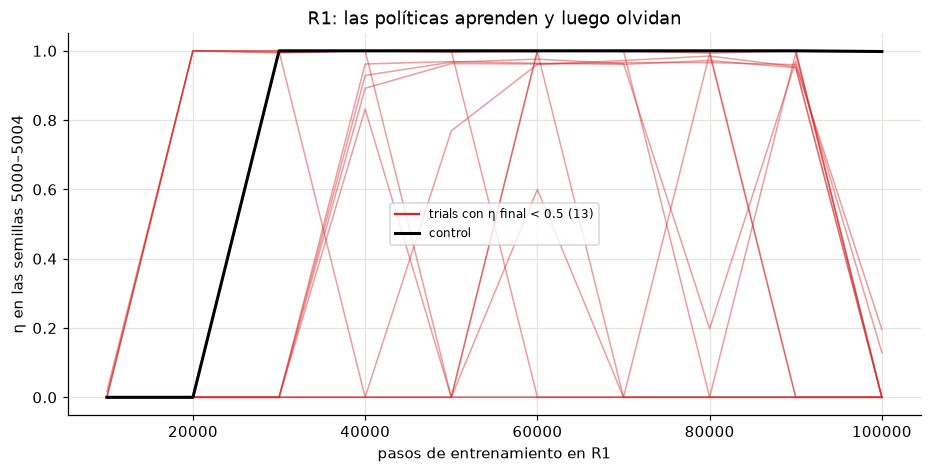

In [51]:
# (c) Brecha en el tiempo: políticas entrenadas en R1 dentro de la búsqueda (10 evaluaciones cada una)
curvas_r1 = {}
for t in aleatoria["trial_id"]:
    c = pd.read_csv(CARPETA_HPO / f"trial_{t:03d}" / "curve.csv")
    curvas_r1[t] = c.loc[c["nivel"] == "R1", "eta"].to_numpy()
curvas_r1 = pd.DataFrame(curvas_r1).T                     # fila = trial, columna = evaluación
aprendio = curvas_r1.max(axis=1) >= 0.9
final_malo = curvas_r1.iloc[:, -1] < 0.5
print(f"Trials con η final < 0.5 en R1: {final_malo.sum()} de {len(curvas_r1)}")
print(f"  de ellos, llegaron antes a η ≥ 0.9 (aprendieron y olvidaron): {(aprendio & final_malo).sum()}")
print(f"  nunca llegaron a 0.9: {(~aprendio & final_malo).sum()}")
print(f"Caídas de η ≥ 0.9 a < 0.5 entre dos evaluaciones seguidas (todos los trials): "
      f"{((curvas_r1.shift(-1, axis=1) < 0.5) & (curvas_r1 >= 0.9)).sum().sum()}")

pasos = np.arange(1, curvas_r1.shape[1] + 1) * BUSQUEDA["objetivo"]["evaluar_cada"]   # 10 000, 20 000, …
fig, ax = plt.subplots(figsize=(10, 4.5))
for t, fila in curvas_r1[final_malo].iterrows():
    ax.plot(pasos, fila, color="C3", alpha=0.45, lw=1)
ax.plot([], [], color="C3", label=f"trials con η final < 0.5 ({final_malo.sum()})")
control_r1 = pd.read_csv(CARPETA_CONTROL / "curve.csv").query("nivel == 'R1'")["eta"].to_numpy()
ax.plot(pasos, control_r1, color="k", lw=2, label="control")
ax.set_xlabel("pasos de entrenamiento en R1")
ax.set_ylabel("η en las semillas 5000–5004")
ax.set_title("R1: las políticas aprenden y luego olvidan")
ax.legend(fontsize=8)
fig.savefig(FIGURAS / "fig19_parcial_olvido_R1.png", bbox_inches="tight")
plt.show()

### 7.3 Mitigación

| Riesgo | Evidencia | Mitigación aplicada | Mitigación propuesta |
|---|---|---|---|
| Fuga de información de evaluación | — | Particiones de semillas disjuntas (entrenamiento 1000–1003, ajuste 5000–5019, reporte 9000–9029, comprobadas con `assert`); normalización de observaciones congelada al evaluar | — |
| Memorizar episodios (a) | Brecha de episodios ≈ 0 | Episodios nuevos en cada reinicio; evaluación con semillas nunca vistas | — |
| Depender de la física de entrenamiento (b) | Brecha R3→R1 de hasta 0.97 con base y margen; R3→R4 ≈ 0.07–0.09 en los tres conjuntos | Selección de atributos: quitar la fase (sin_fase) elimina la brecha en R1 | Entrenar con varios niveles a la vez (randomización de dominio) |
| Olvidar lo aprendido (c) | 13 de 60 trials terminan con η < 0.5 en R1 | Métrica de eficiencia muestral (premia aprender rápido y estable, no solo el final); regla de decisión con umbral | Guardar el mejor checkpoint según las semillas de ajuste (early stopping) |
| Elegir por ruido | Mejora del mejor trial (+0.019) concentrada en R2, con una semilla | Umbral de 0.02 fijado antes de correr; se mantiene la configuración inicial | Confirmar el top-3 con 3 semillas de PPO |

Lo que cuesta la mitigación propuesta para (c), sin entrenar: si en vez del modelo final se guardara el mejor checkpoint, ¿cuántos trials terminarían bien en R1?

In [52]:
# Cota optimista: el mejor punto se elige con las mismas 5 semillas con que se mide; habría que confirmarlo en reporte
mejor_punto = curvas_r1.max(axis=1)
pd.DataFrame({
    "modelo final": [(curvas_r1.iloc[:, -1] >= 0.9).sum(), curvas_r1.iloc[:, -1].mean()],
    "mejor punto de control": [(mejor_punto >= 0.9).sum(), mejor_punto.mean()],
}, index=["trials con η R1 ≥ 0.9", "η R1 medio"]).round(3)

,modelo final,mejor punto de control
trials con η R1 ≥ 0.9,44.000,56.000
η R1 medio,0.756,0.952


**Lectura**

- **No hay brecha de episodios:** la política rinde igual en los episodios de entrenamiento que en semillas nuevas del mismo nivel (diferencia ≤ 0.01). PPO no memoriza episodios.
- **La brecha que importa es la de fidelidad**, que es justo la pregunta de la tesis. Hacia R4 es pequeña y estable (≈ 0.07–0.09, igual en los tres conjuntos). Hacia R1 depende de los atributos: con base o margen la política falla en 5 de 6 folds; con sin_fase, en ninguno.
- **Hay una tercera brecha, en el tiempo:** en R1 las políticas aprenden y luego olvidan. Esto no lo resuelve la búsqueda de hiperparámetros, porque aparece con configuraciones muy distintas. Guardar el mejor checkpoint subiría los trials con η R1 ≥ 0.9 de 44 a 56 de 60 (η R1 medio de 0.76 a 0.95). Es una cota optimista, porque el punto se elige con las mismas semillas con que se mide: hay que confirmarlo con las semillas de reporte.

## 8. Análisis, riesgos y conclusiones

### 8.1 Análisis general

Con el entorno congelado en Var3, PPO entrenado en R3 alcanza un η de 0.964 a 0.967 en su propio nivel, según el conjunto de atributos, con una desviación entre folds que no pasa de 0.008. Eso lo deja ligeramente por encima de la mejor heurística (0.954) y muy por encima de las políticas sin control (0.47 a 0.49). Dentro del nivel de entrenamiento, entonces, el problema está resuelto y los tres conjuntos de atributos son prácticamente equivalentes. Las diferencias aparecen recién al evaluar fuera de R3, y es ahí donde se concentra todo lo interesante del estudio.

La búsqueda de hiperparámetros confirmó que la configuración que veníamos usando desde el Sprint 3 ya estaba cerca de lo mejor del espacio. De 60 configuraciones, solo 3 la superaron y la mejor lo hizo por 0.019, por debajo del umbral de 0.02 que fijé antes de correr, así que mantengo la configuración inicial. Además, la mejora de ese trial sale casi entera de R2 y se midió con una sola semilla, por lo que no puedo distinguirla del ruido. Lo más útil que dejó la búsqueda no es una configuración nueva, sino dos observaciones: los hiperparámetros cambian la velocidad con que se aprende, pero casi no el η final (entre 0.93 y 0.97 en R2–R4 en todos los casos comparados), y el hiperparámetro que más pesa es n_steps, con 512 por entorno como el mejor valor en promedio.


### 8.2 Contraste con las hipótesis

La hipótesis H1 queda refutada. Pedía que cada par de niveles consecutivos produjera un η distinto en al menos una política de referencia, y el par R2–R3 no lo cumple con ninguna. Pedía también que el retorno y η estuvieran alineados con un Spearman de al menos 0.9 en cada nivel, y eso solo ocurre en R4 (0.997); en R1, R2 y R3 los valores son 0.81, 0.86 y 0.865. La recompensa sigue a η en términos generales, pero no lo ordena con la precisión que yo había exigido.

La hipótesis H4 queda respaldada, con la reserva de que se apoya en tres folds. Las variables que dependen del nivel tienen importancia negativa fuera de R3: la fase llega a −0.31 en R1 y −0.065 en R2 con el conjunto base, y tanto la fase como el margen de control llegan a −0.32 en R1 con el conjunto margen. Que la importancia sea negativa significa que al desordenar esa variable la política funciona mejor, es decir, que la variable la confunde cuando cambia la física. Al quitar la fase, la brecha media fuera de R3 baja de 0.260 con base a 0.032 con sin_fase, muy por encima de los 0.05 que pedía la hipótesis. La reserva es que la desviación de estas importancias entre folds es grande (alrededor de 0.5 en R1), porque el efecto aparece solo en los folds que fallan, y que la brecha hacia R4 no baja sino que sube un poco, de 0.075 a 0.093.

La hipótesis general, H2 y H3 todavía no se pueden contrastar, porque requieren la matriz de evaluación cruzada 4×4 y el entrenamiento con currículo, que son los objetivos OE2 y OE3. Lo único que adelantan estos resultados es que la brecha de R3 hacia R1 puede ser muy grande o nula según los atributos, por lo que cualquier medida de asimetría tendrá que fijar primero el conjunto de atributos, y con sin_fase ya decidido esa comparación queda en condiciones de hacerse.

### 8.3 Riesgos

El primer riesgo es estadístico. Los resultados de atributos se apoyan en tres semillas de PPO, cada trial de la búsqueda en una sola, y cada evaluación intermedia en cinco episodios. En R1 el problema se agrava porque η es casi binario, o la política lleva al enjambre a la rama correcta o no lo lleva, y entonces una sola evaluación puede mover mucho la nota. Por eso fijé de antemano el umbral de decisión de 0.02 y no adopté el mejor trial, y por eso propongo confirmar las tres mejores configuraciones con tres semillas antes de cambiar nada.

El segundo riesgo es la inestabilidad del aprendizaje en R1. En 13 de los 60 trials la política entrenada en R1 termina con η menor a 0.5, y en 11 de ellos había llegado antes a 0.9 o más; aprende y luego olvida. Esto aparece con configuraciones muy distintas, así que no es un problema de hiperparámetros. Si en lugar del modelo final se guardara el mejor checkpoint, los trials que terminan bien en R1 pasarían de 44 a 56, aunque esa cifra es optimista porque el punto se elige con las mismas semillas con que se mide.

El tercer riesgo tiene que ver con la métrica. Que η esté saturado cerca de 0.95 en R2 y R3 y que el Spearman retorno–η quede por debajo de 0.9 en tres niveles significa que η no siempre distingue lo que quiero medir y que la recompensa no está perfectamente alineada con él. Lo mitigo reportando siempre las métricas secundarias junto a η, en particular el tránsito y el esfuerzo.

El cuarto riesgo es el uso de las semillas de reporte. En el Sprint 2 se usaron para elegir el entorno y en el Sprint 3 para comparar los atributos, de modo que ya no están completamente intactas. Para este parcial todas las decisiones nuevas, la búsqueda, la importancia y las ablaciones de atributos, se tomaron con las semillas de ajuste, y las particiones se comprueban con `assert` en el código. Aun así, para los resultados finales de la tesis convendría reservar un bloque de semillas de reporte que no se haya usado nunca.

El último riesgo es de validez externa. Los cuatro niveles son simulados, R4 incluido, así que lo que mido es la generalización entre simuladores de distinta fidelidad y no la transferencia a un sistema físico. Esa es la pregunta de la tesis, pero conviene decirlo explícitamente para no sobrestimar el alcance.

### 8.4 Conclusiones

En el nivel en que se entrena, PPO resuelve la tareade la forma que entrenado en R3, llega a un η de 0.964 a 0.967 según el conjunto de atributos, con una desviación entre semillas que no pasa de 0.008, y rinde igual en los episodios de entrenamiento que en episodios nuevos del mismo nivel, con una diferencia máxima de 0.010. La política no memoriza episodios; lo que puede aprender de más es la física del nivel en que se entrenó.

Esa dependencia de la física la decide sobre todo la observación. Con los tres conjuntos de atributos la política es igual de buena en R3, pero al evaluarla en R1 el conjunto base falla en dos de tres semillas, el conjunto margen en las tres y el conjunto sin_fase en ninguna, con η de 0.969 en R1. La brecha media fuera de R3 baja de 0.260 con base a 0.032 con sin_fase. La importancia por permutación apunta a la misma causa: la fase del pulso y el margen de control, que solo tienen sentido con flujo, tienen importancias de −0.31 y −0.32 en R1, es decir, la política funciona mejor cuando se le desordenan. Quitar la fase no es gratis en todos los niveles, porque la brecha hacia R4 sube de 0.075 a 0.093, y esa brecha hacia R4, de 0.07 a 0.09, aparece con los tres conjuntos, de modo que el movimiento browniano introduce una diferencia que la selección de atributos no elimina.

R2 y R3 no se distinguen en η con ninguna de las políticas que medí: 0.955 y 0.954 con la heurística de rama, 0.950 y 0.950 con la perpendicular, y 0.959 y 0.966 con PPO sin_fase. Tampoco se distinguen en lo difícil que es aprenderlos, porque en los 60 trials, que entrenan ambos niveles con los mismos hiperparámetros y la misma semilla, la diferencia de eficiencia muestral es 0.004, con IC 95 % de −0.015 a 0.023. Sí difieren en el tránsito y en el esfuerzo, aunque parte de esa diferencia puede deberse a que el pulso empieza siempre en la misma fase. Con esto la hipótesis H1 queda refutada para el par R2–R3, y la recompensa solo alcanza la alineación exigida con η en R4, con un Spearman de 0.997 frente a 0.81–0.87 en los otros niveles.

La búsqueda de 60 configuraciones no encontró una mejor que la inicial según la regla fijada antes de correr: solo 3 la superaron y la mejor lo hizo por 0.019, por debajo del umbral de 0.02, con una ventaja concentrada en R2 y medida con una sola semilla. El hiperparámetro que más pesa es n_steps, con una importancia de 0.61, y 512 pasos por entorno, el valor que ya usaba, es el de mejor eficiencia media. La eficiencia muestral varió entre 0.66 y 0.89 a lo largo de la búsqueda, mientras que en las cuatro configuraciones que comparé en detalle el η final en R2–R4 quedó entre 0.93 y 0.97.

El aprendizaje en R1 es inestable. En 13 de los 60 trials la política entrenada en R1 termina con η menor a 0.5, y en 11 de ellos había llegado antes a 0.9 o más. Si se conservara el mejor punto del entrenamiento en lugar del modelo final, las políticas con η de al menos 0.9 en R1 pasarían de 44 a 56, una cifra optimista porque ese punto se elige con las mismas semillas con que se mide.

Estos resultados dejan fijados el entorno, el conjunto de atributos sin_fase y la configuración de PPO, pero no permiten todavía contrastar la hipótesis principal. Lo medido hasta aquí es la generalización de políticas entrenadas en R3; la hipótesis general, la asimetría de la brecha (H2) y el efecto del currículo (H3) necesitan la matriz de evaluación cruzada 4×4 y el entrenamiento con currículo.

## 9. Trabajo futuro, reproducibilidad, referencias y anexos

### 9.1 Trabajo futuro 

Con el entorno, los atributos y los hiperparámetros ya fijados, se dedica a la matriz de evaluación cruzada 4×4, que es el objetivo OE2. Entrenaré una política PPO en cada nivel con el conjunto sin_fase y la configuración inicial, con tres semillas por nivel, y evaluaré cada una en los cuatro niveles. Eso da el FidelityGap de cada par de niveles en ambos sentidos y permite contrastar por primera vez la hipótesis H2 sobre la asimetría de la brecha. 

En esa misma matriz incorporaré lo que aprendí sobre el olvido en R1. Durante el entrenamiento evaluaré la política cada 10 000 pasos con las semillas de ajuste y guardaré, además del modelo final, el mejor checkpoint. Los resultados se reportarán con las semillas de reporte, de modo que la elección del checkpoint no contamine la medición. Para eso reservaré un bloque nuevo de semillas de reporte que no se haya usado en ningún sprint anterior.

Antes de cerrar la búsqueda de hiperparámetros quiero confirmar las tres mejores configuraciones con tres semillas cada una, porque la ventaja del mejor trial se midió con una sola semilla y se concentra en R2. Si alguna supera a la configuración inicial por el umbral de 0.02 con varias semillas, la adoptaré; si no, la configuración inicial queda confirmada. Más adelante podría ampliar el espacio con gae_lambda y clip_range, que Andrychowicz et al. (2021) señalan como influyentes en PPO, pero no lo considero prioritario dado que los hiperparámetros cambian la velocidad de aprendizaje y no el resultado final.

La decisión sobre R2 y R3 la discutiré con el asesor antes de construir la matriz, porque condiciona cómo se lee esa parte de los resultados. Si se mantiene el entorno, la brecha entre R2 y R3 se medirá con el tránsito, el esfuerzo y la eficiencia muestral además de η. Si se decide hacer la tarea más exigente, habría que reabrir el Sprint 2 y repetir la línea base.

Una vez terminada la matriz, el sprint siguiente será el entrenamiento con currículo R1→R4 (OE3), que permite contrastar H3 y la hipótesis general, y después la repetición de la matriz con DreamerV3 (OE5).

### 9.2 Reproducibilidad

Todo el proyecto está en el repositorio https://github.com/BlackFermions/TesisMIA_Magnetic-Nanoswarm_RL, en la rama `sprint5-busquedaHiperparametros`. Para repetirlo desde cero en Windows basta con clonar el repositorio, crear el entorno e instalar las dependencias con las versiones fijadas en `requirements.txt`:

```powershell
git clone https://github.com/BlackFermions/TesisMIA_Magnetic-Nanoswarm_RL.git
cd TesisMIA_Magnetic-Nanoswarm_RL
python -m venv .venv; .\.venv\Scripts\Activate.ps1
pip install -r requirements.txt; pip install -e . --no-deps
```

El informe completo se reproduce abriendo este notebook y ejecutando todas las celdas. La única celda pesada es la de la sección 6.1, que repite la búsqueda de 60 trials en unas seis horas con ocho núcleos; si ya existen sus resultados, la celda los lee y no vuelve a entrenar. Una corrida individual se repite con un solo comando, por ejemplo la política sin_fase entrenada en R3 con la semilla de PPO 1000, y la búsqueda y la configuración inicial con los suyos:

```powershell
python scripts/train.py --feature-sets sin_fase --condition R3 --seeds 0   # PPO semilla 1000
python scripts/hpo.py --sampler random                                     # 60 trials (search.yaml)
python scripts/hpo.py --control                                            # configuración inicial
```

No usé MLflow, que en la clase aparece como una opción, porque cada pieza que registraría ya queda guardada en disco junto a la corrida. Los parámetros y las semillas de cada experimento están en `configs/train/search.yaml` y en el `meta.json` de cada carpeta; las métricas por evaluación, en `curve.csv`; el estudio completo de Optuna, con todos los trials y sus notas parciales, en `journal.log`; los modelos de las corridas de atributos, en `model.zip` junto con la normalización en `obs_rms.npz`; y la comparación de todas las corridas, en `results/tables/parcial_tablero.csv`. Los trials de la búsqueda no guardan el modelo, porque la decisión se toma con la curva y guardar 240 modelos no aportaba nada. La trazabilidad de quién, cuándo y con qué código la da la celda de la sección 0, que imprime la fecha, el commit de git y las versiones de los paquetes. Los datos no tienen un hash porque no son un archivo externo: se generan con el simulador a partir de las semillas, así que su versión es el commit del código más la semilla de cada episodio.

### 9.3 Referencias

- Agarwal, R., Schwarzer, M., Castro, P. S., Courville, A., y Bellemare, M. G. (2021). Deep reinforcement learning at the edge of the statistical precipice. *Advances in Neural Information Processing Systems*, 34, 29304–29320.
- Akiba, T., Sano, S., Yanase, T., Ohta, T., y Koyama, M. (2019). Optuna: A next-generation hyperparameter optimization framework. *Proceedings of the 25th ACM SIGKDD International Conference on Knowledge Discovery & Data Mining*, 2623–2631.
- Andrychowicz, M., Raichuk, A., Stańczyk, P., Orsini, M., Girgin, S., Marinier, R., Hussenot, L., Geist, M., Pietquin, O., Michalski, M., Gelly, S., y Bachem, O. (2021). What matters for on-policy deep actor-critic methods? A large-scale study. *International Conference on Learning Representations (ICLR)*.
- Bengio, Y., Louradour, J., Collobert, R., y Weston, J. (2009). Curriculum learning. *Proceedings of the 26th International Conference on Machine Learning (ICML)*, 41–48.
- Bergstra, J., y Bengio, Y. (2012). Random search for hyper-parameter optimization. *Journal of Machine Learning Research*, 13, 281–305.
- Breiman, L. (2001). Random forests. *Machine Learning*, 45(1), 5–32.
- Hafner, D., Pasukonis, J., Ba, J., y Lillicrap, T. (2025). Mastering diverse control tasks through world models. *Nature*, 640, 647–653.
- Kirk, R., Zhang, A., Grefenstette, E., y Rocktäschel, T. (2023). A survey of zero-shot generalisation in deep reinforcement learning. *Journal of Artificial Intelligence Research*, 76, 201–264.
- Medany, M., Piglia, L., Achenbach, L., Mukkavilli, S. K., y Ahmed, D. (2025). Model-based reinforcement learning for ultrasound-driven autonomous microrobots. *Nature Machine Intelligence*, 7, 1076–1090.
- Raffin, A., Hill, A., Gleave, A., Kanervisto, A., Ernestus, M., y Dormann, N. (2021). Stable-Baselines3: Reliable reinforcement learning implementations. *Journal of Machine Learning Research*, 22(268), 1–8.
- Schulman, J., Wolski, F., Dhariwal, P., Radford, A., y Klimov, O. (2017). Proximal policy optimization algorithms. *arXiv:1707.06347*.
- Tobin, J., Fong, R., Ray, A., Schneider, J., Zaremba, W., y Abbeel, P. (2017). Domain randomization for transferring deep neural networks from simulation to the real world. *IEEE/RSJ International Conference on Intelligent Robots and Systems (IROS)*, 23–30.
- Towers, M., Kwiatkowski, A., Terry, J., Balis, J. U., De Cola, G., Deleu, T., Goulão, M., Kallinteris, A., Krimmel, M., KG, A., Perez-Vicente, R., Pierré, A., Schulhoff, S., Tai, J. J., Tan, H., y Younis, O. G. (2024). Gymnasium: A standard interface for reinforcement learning environments. *arXiv:2407.17032*.
- Watanabe, S., Bansal, A., y Hutter, F. (2023). PED-ANOVA: Efficiently quantifying hyperparameter importance in arbitrary subspaces. *Proceedings of the 32nd International Joint Conference on Artificial Intelligence (IJCAI)*, 4389–4396.

### 9.4 Anexo: artefactos generados

La celda siguiente lista las tablas y figuras que produce este notebook y comprueba que existan en disco, para que el registro de artefactos no dependa de lo que yo recuerde haber guardado.

In [75]:
ARTEFACTOS = {
    "results/tables/parcial_baseline_episodios.csv": "4.3 Línea base: un episodio por fila",
    "results/tables/parcial_baseline_resumen.csv": "4.3 Línea base: η e IC 95 % por nivel y política",
    "results/figures/fig13_parcial_baseline.png": "4.3 Línea base por nivel",
    "results/tables/parcial_importancia_episodios.csv": "5.3 Importancia por permutación: un episodio por fila",
    "results/tables/parcial_importancia.csv": "5.3 Importancia por grupo, conjunto y nivel",
    "results/figures/fig14_parcial_importancia_4niveles.png": "5.3 Importancia en los 4 niveles",
    "experiments/hpo/random/trials.csv": "6.1 Los 60 trials de la búsqueda",
    "experiments/hpo/random/journal.log": "6.1 Estudio de Optuna (retomable)",
    "results/tables/parcial_hpo_top5.csv": "6.2 Top-5 frente al control",
    "results/tables/parcial_hpo_podio.csv": "6.2 Podio top-k con nota de decisión",
    "results/figures/fig15_parcial_hpo_evolucion.png": "6.2 Métrica frente a trial",
    "results/tables/parcial_hpo_importancia.csv": "6.2 Importancia de hiperparámetros (PED-ANOVA)",
    "results/figures/fig16a_parcial_hpo_importancia.png": "6.2 Importancia de hiperparámetros",
    "results/figures/fig16b_parcial_hpo_eficiencia_por_valor.png": "6.2 Eficiencia por valor de cada hiperparámetro",
    "results/figures/fig17_parcial_hpo_slice.png": "6.2 Slice plot: eficiencia frente a cada hiperparámetro",
    "results/figures/fig21_parcial_hpo_costo_beneficio.png": "6.2 Costo frente a beneficio de cada trial",
    "results/figures/fig23_parcial_R2_R3.png": "6.3.1 R2 frente a R3: η, tránsito y esfuerzo",
    "results/tables/parcial_atributos_por_fold.csv": "6.3.2 η por conjunto, fold y nivel",
    "results/tables/parcial_atributos_resumen.csv": "6.3.2 η media ± desv. y brecha por conjunto",
    "results/figures/fig18_parcial_atributos_por_fold.png": "6.3.2 Ablación de atributos por fold",
    "results/tables/parcial_ablacion_hp.csv": "6.3.3 Control frente a mejor, mediana y peor trial",
    "results/figures/fig22_parcial_hpo_curvas_nivel.png": "6.3.3 Curvas de evaluación por nivel",
    "results/tables/parcial_tablero.csv": "7.1 Tablero de corridas",
    "results/tables/parcial_brecha_episodios.csv": "7.2 Brecha de episodios",
    "results/figures/fig20_parcial_train_vs_val.png": "7.2 Curva de aprendizaje: entrenamiento frente a validación",
    "results/tables/parcial_brecha_fidelidad.csv": "7.2 Brecha de fidelidad por fold",
    "results/figures/fig19_parcial_olvido_R1.png": "7.2 Olvido en R1",
}
anexo = pd.DataFrame([{"archivo": a, "contenido": c, "existe": (ROOT / a).exists()} for a, c in ARTEFACTOS.items()])
print(f"Faltan {(~anexo['existe']).sum()} de {len(anexo)}")
anexo

Faltan 0 de 27


,archivo,contenido,existe
0,results/tables/parcial_baseline_episodios.csv,4.3 Línea base: un episodio por fila,True
1,results/tables/parcial_baseline_resumen.csv,4.3 Línea base: η e IC 95 % por nivel y política,True
2,results/figures/fig13_parcial_baseline.png,4.3 Línea base por nivel,True
3,results/tables/parcial_importancia_episodios.csv,5.3 Importancia por permutación: un episodio p...,True
4,results/tables/parcial_importancia.csv,"5.3 Importancia por grupo, conjunto y nivel",True
5,results/figures/fig14_parcial_importancia_4niv...,5.3 Importancia en los 4 niveles,True
6,experiments/hpo/random/trials.csv,6.1 Los 60 trials de la búsqueda,True
7,experiments/hpo/random/journal.log,6.1 Estudio de Optuna (retomable),True
8,results/tables/parcial_hpo_top5.csv,6.2 Top-5 frente al control,True
9,results/tables/parcial_hpo_podio.csv,6.2 Podio top-k con nota de decisión,True


In [76]:
print(json.dumps(run_metadata(), indent=2, ensure_ascii=False))
print(f"Tiempo total del notebook: {(time.time() - T_INICIO) / 60:.1f} min")

{
  "fecha": "2026-11-13T14:51:41",
  "git_commit": "99a45e1 (con cambios sin commit)",
  "python": "3.12.7",
  "plataforma": "Windows-11-10.0.26300-SP0",
  "numpy": "2.5.3",
  "pandas": "3.0.6"
}
Tiempo total del notebook: 985.6 min
